# Evaluación — Red Neuronal Multicapa (MLP) para clasificación
## Dataset: *Bank Marketing* (UCI Machine Learning Repository)

### Contexto del problema

Un banco portugués realizó **campañas de marketing telefónico** para ofrecer a sus clientes un **depósito a plazo**. Por cada cliente contactado se registraron sus datos personales, su situación financiera y el historial de contactos de la campaña.

**Objetivo:** construir un modelo que prediga si un cliente **contratará el depósito a plazo** (`y = "yes"`) o **no** (`y = "no"`).

| | |
|---|---|
| **Tipo de problema** | Clasificación **binaria** |
| **Registros** | 45.211 clientes |
| **Variables de entrada** | 16 (7 numéricas y 9 categóricas) |
| **Variable objetivo** | `y` ("yes" / "no") |
| **Fuente** | [UCI Machine Learning Repository — Bank Marketing](https://archive.ics.uci.edu/dataset/222/bank+marketing) |
| **Licencia** | CC BY 4.0 |
| **Cita** | Moro, S., Cortez, P. & Rita, P. (2014). *A data-driven approach to predict the success of bank telemarketing.* Decision Support Systems, 62, 22–31. |

---
**Asignatura:** DLY0100 – Deep Learning · **Evaluación Parcial N° 1**
**Integrantes:** _Nombre Apellido 1_ · _Nombre Apellido 2_
**Framework:** PyTorch (+ scikit-learn para preprocesamiento y métricas)

## Índice

0. Configuración del entorno
1. Carga de los datos
2. Diccionario de variables
3. Análisis exploratorio (EDA)
4. Preprocesamiento (justificado)
5. Fundamentos: funciones de activación, error y salida programadas desde cero
6. Definición del modelo MLP en PyTorch
7. Modelo base y experimentos controlados: épocas, tasa de aprendizaje y batch size
8. Comparación de funciones de activación
9. Comparación de funciones de pérdida (error)
10. Optimización y regularización (dropout, batch normalization, L2, optimizadores)
11. Arquitectura y ajuste de hiperparámetros
12. Modelo final: entrenamiento, ajuste del umbral y evaluación en test
13. Validación cruzada estratificada
14. Análisis crítico de métricas y propuestas de mejora
15. Conclusiones
16. Referencias

## 0. Configuración del entorno

Se usa **PyTorch** para la red neuronal y **scikit-learn** sólo para el preprocesamiento (`ColumnTransformer`) y el cálculo de métricas.
Se fija una **semilla** global para que todos los experimentos sean reproducibles y comparables entre sí: cuando comparamos dos configuraciones, la única diferencia debe ser el parámetro que estamos variando, no el azar de la inicialización.

> En Google Colab todas estas librerías vienen preinstaladas. En local: `pip install -r requirements.txt`.

In [1]:
import io, time, random, zipfile, urllib.request, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             classification_report, precision_recall_curve, roc_curve)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.float_format", "{:.4f}".format)

SEED = 42
def fijar_semilla(seed=SEED):
    """Fija todas las fuentes de aleatoriedad (Python, NumPy, PyTorch)."""
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

fijar_semilla()
torch.set_num_threads(4)          # resultados estables y comparables entre ejecuciones en CPU
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| dispositivo:", DEVICE)

PyTorch 2.11.0+cpu | dispositivo: cpu


## 1. Carga de los datos

Se usa el archivo `bank_marketing.csv` entregado por el docente (misma información que `bank-full.csv` de UCI). Si el archivo no está en la carpeta, la celda lo **descarga automáticamente desde UCI**, de modo que el notebook se ejecuta igual en Colab o en local sin pasos manuales.

In [2]:
RUTA_CSV = Path("bank_marketing.csv")
URL_UCI = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"

if RUTA_CSV.exists():
    df = pd.read_csv(RUTA_CSV)
    origen = "archivo local"
else:
    with urllib.request.urlopen(URL_UCI) as resp:
        zip_externo = zipfile.ZipFile(io.BytesIO(resp.read()))
    zip_interno = zipfile.ZipFile(io.BytesIO(zip_externo.read("bank.zip")))  # viene comprimido dos veces
    df = pd.read_csv(zip_interno.open("bank-full.csv"), sep=";")
    origen = "UCI"

print(f"Datos cargados desde {origen}: {df.shape[0]:,} filas x {df.shape[1]} columnas")

Datos cargados desde archivo local: 45,211 filas x 17 columnas


## 2. Diccionario de variables

**Datos del cliente**

| Variable | Tipo | Descripción |
|---|---|---|
| `age` | numérica | Edad |
| `job` | categórica | Tipo de trabajo (`admin.`, `blue-collar`, `entrepreneur`, `housemaid`, `management`, `retired`, `self-employed`, `services`, `student`, `technician`, `unemployed`, `unknown`) |
| `marital` | categórica | Estado civil (`married`, `single`, `divorced` — "divorced" incluye viudos) |
| `education` | categórica | Nivel educacional (`primary`, `secondary`, `tertiary`, `unknown`) |
| `default` | binaria | ¿Tiene créditos en mora? (`yes` / `no`) |
| `balance` | numérica | Saldo promedio anual, en euros (puede ser negativo) |
| `housing` | binaria | ¿Tiene crédito hipotecario? |
| `loan` | binaria | ¿Tiene crédito de consumo? |

**Último contacto de la campaña actual**

| Variable | Tipo | Descripción |
|---|---|---|
| `contact` | categórica | Medio de contacto (`cellular`, `telephone`, `unknown`) |
| `day` | numérica | Día del mes del último contacto |
| `month` | categórica | Mes del último contacto (`jan` … `dec`) |
| `duration` | numérica | Duración del último contacto, en segundos ⚠️ *(ver nota importante más abajo)* |

**Otros atributos**

| Variable | Tipo | Descripción |
|---|---|---|
| `campaign` | numérica | N° de contactos realizados a este cliente en esta campaña (incluye el último) |
| `pdays` | numérica | Días transcurridos desde el último contacto de una campaña **anterior** (`-1` = nunca fue contactado antes) |
| `previous` | numérica | N° de contactos realizados antes de esta campaña |
| `poutcome` | categórica | Resultado de la campaña anterior (`success`, `failure`, `other`, `unknown`) |

**Variable objetivo**

| Variable | Tipo | Descripción |
|---|---|---|
| `y` | binaria | ¿El cliente contrató el depósito a plazo? (`yes` / `no`) |

## 3. Análisis exploratorio (EDA)

Antes de preprocesar revisamos tipos, rangos, valores faltantes, desbalance de clases y la relación de cada variable con el objetivo. Cada hallazgo de esta sección motiva una decisión del preprocesamiento (sección 4).

In [3]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 8.1 MB


In [5]:
df.describe().round(2)

,age,balance,day,duration,campaign,pdays,previous
count,45211.0000,45211.0000,45211.0000,45211.0000,45211.0000,45211.0000,45211.0000
mean,40.9400,1362.2700,15.8100,258.1600,2.7600,40.2000,0.5800
std,10.6200,3044.7700,8.3200,257.5300,3.1000,100.1300,2.3000
min,18.0000,-8019.0000,1.0000,0.0000,1.0000,-1.0000,0.0000
25%,33.0000,72.0000,8.0000,103.0000,1.0000,-1.0000,0.0000
50%,39.0000,448.0000,16.0000,180.0000,2.0000,-1.0000,0.0000
75%,48.0000,1428.0000,21.0000,319.0000,3.0000,-1.0000,0.0000
max,95.0000,102127.0000,31.0000,4918.0000,63.0000,871.0000,275.0000


### 3.1 Distribución de la variable objetivo

,cantidad,porcentaje (%)
y,,
no,39922,88.3000
yes,5289,11.7000


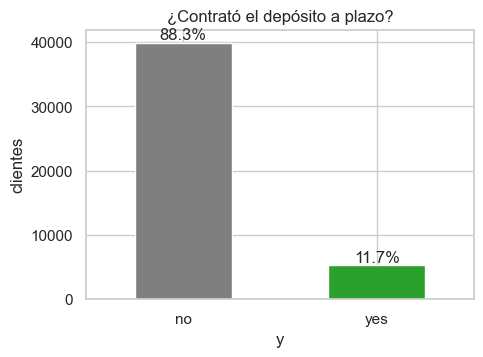

Por cada cliente 'yes' hay 7.55 clientes 'no'.
Accuracy de un modelo trivial que siempre dice 'no': 0.883


In [6]:
conteo = df["y"].value_counts()
porcentaje = df["y"].value_counts(normalize=True).mul(100).round(1)
display(pd.DataFrame({"cantidad": conteo, "porcentaje (%)": porcentaje}))

fig, ax = plt.subplots(figsize=(5, 3.5))
conteo.plot(kind="bar", color=["tab:gray", "tab:green"], rot=0, ax=ax,
            title="¿Contrató el depósito a plazo?")
ax.set_ylabel("clientes")
for i, v in enumerate(conteo):
    ax.text(i, v, f"{porcentaje.iloc[i]}%", ha="center", va="bottom")
plt.show()

RATIO_NEG_POS = conteo["no"] / conteo["yes"]
print(f"Por cada cliente 'yes' hay {RATIO_NEG_POS:.2f} clientes 'no'.")
print(f"Accuracy de un modelo trivial que siempre dice 'no': {conteo['no']/len(df):.3f}")

**Hallazgo:** el problema está **fuertemente desbalanceado** (~11,7 % de positivos). Consecuencias para el diseño:
- La **accuracy no sirve** como métrica principal (el modelo trivial ya obtiene ~88 %). Usaremos **F1-Score, Precision y Recall de la clase `yes`** y, como métrica independiente del umbral, el **PR-AUC** (*average precision*).
- La partición train/val/test debe ser **estratificada** para mantener la proporción de clases.
- Habrá que probar técnicas para el desbalance: **pérdida ponderada**, *focal loss* y **ajuste del umbral de decisión**.

### 3.2 Valores "unknown" y valores faltantes

In [7]:
print("Celdas vacías (NaN):", df.isna().sum().sum())
print("Filas duplicadas:", df.duplicated().sum())
categoricas_raw = df.select_dtypes(exclude="number").columns.drop("y").tolist()
unknown = pd.Series({c: int((df[c] == "unknown").sum()) for c in categoricas_raw}, name="n_unknown")
(unknown[unknown > 0].to_frame()
    .assign(pct=lambda t: (t.n_unknown / len(df) * 100).round(1)))

Celdas vacías (NaN): 0
Filas duplicadas: 0


,n_unknown,pct
job,288,0.6000
education,1857,4.1000
contact,13020,28.8000
poutcome,36959,81.7000


**Hallazgo:** no hay NaN ni duplicados. `"unknown"` aparece en `job`, `education`, `contact` y `poutcome`. En `poutcome` (82 %) y `contact` (29 %) es tan frecuente que eliminar esas filas destruiría el dataset; además *no conocer el dato* puede ser informativo en sí mismo (p. ej. `poutcome = unknown` ≈ cliente nunca contactado). **Decisión:** tratar `"unknown"` como **una categoría más** en el One-Hot Encoding.

### 3.3 Variables numéricas: distribución y valores extremos

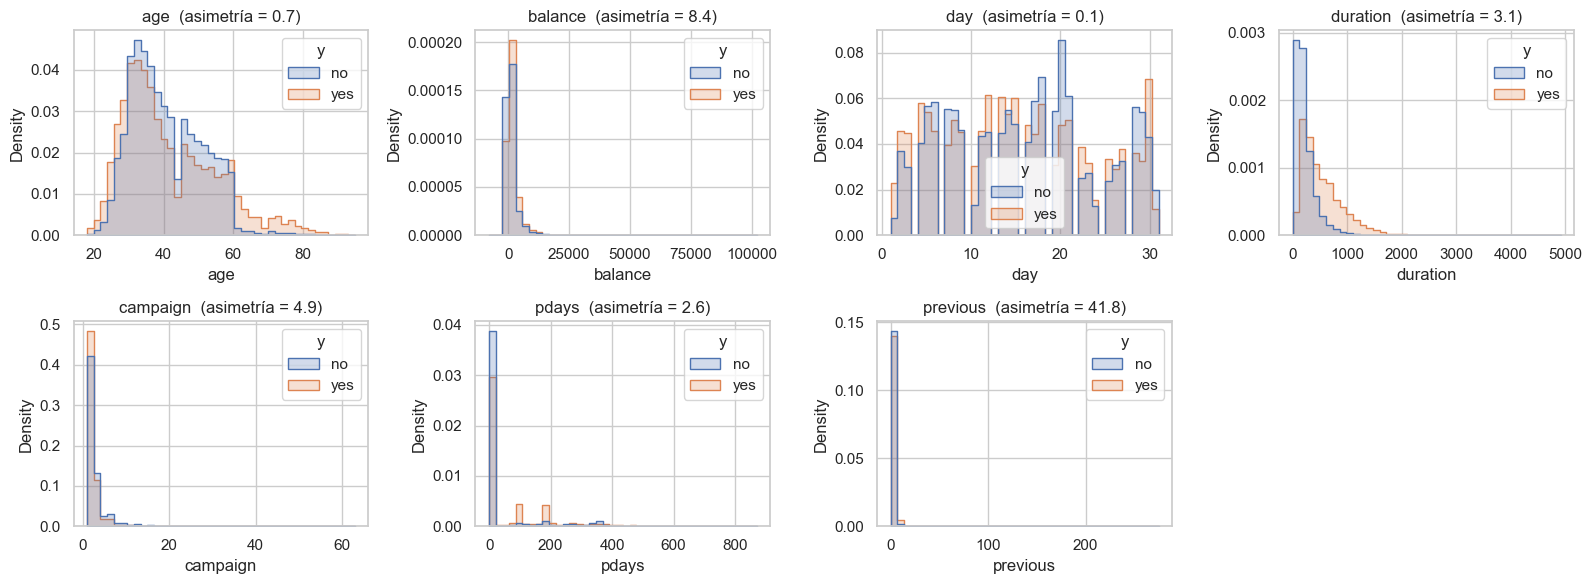

In [8]:
numericas_raw = df.select_dtypes(include="number").columns.tolist()
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, col in zip(axes.ravel(), numericas_raw):
    sns.histplot(data=df, x=col, hue="y", bins=40, ax=ax, stat="density",
                 common_norm=False, element="step")
    ax.set_title(f"{col}  (asimetría = {df[col].skew():.1f})")
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

**Hallazgos:**
- `balance`, `campaign`, `previous` y `pdays` tienen **asimetría muy alta** (colas largas). Con un `StandardScaler` directo, unos pocos valores extremos dominarían la escala y la mayoría de los datos quedaría comprimida cerca de cero, lo que dificulta el aprendizaje del gradiente. **Decisión:** aplicar una transformación logarítmica con signo, `sign(x)·log(1+|x|)`, antes de estandarizar (funciona también con saldos negativos).
- `pdays = -1` (≈ 82 % de los casos) es un **código** ("nunca contactado"), no un número de días. **Decisión:** crear la variable binaria `contactado_antes` y reemplazar `pdays=-1` por 0 antes de transformar, para que la red no interprete -1 como "un día menos que 0".
- `duration` separa muy bien las clases, pero es una **fuga de información** (ver 3.5).

### 3.4 Variables categóricas: tasa de conversión por categoría

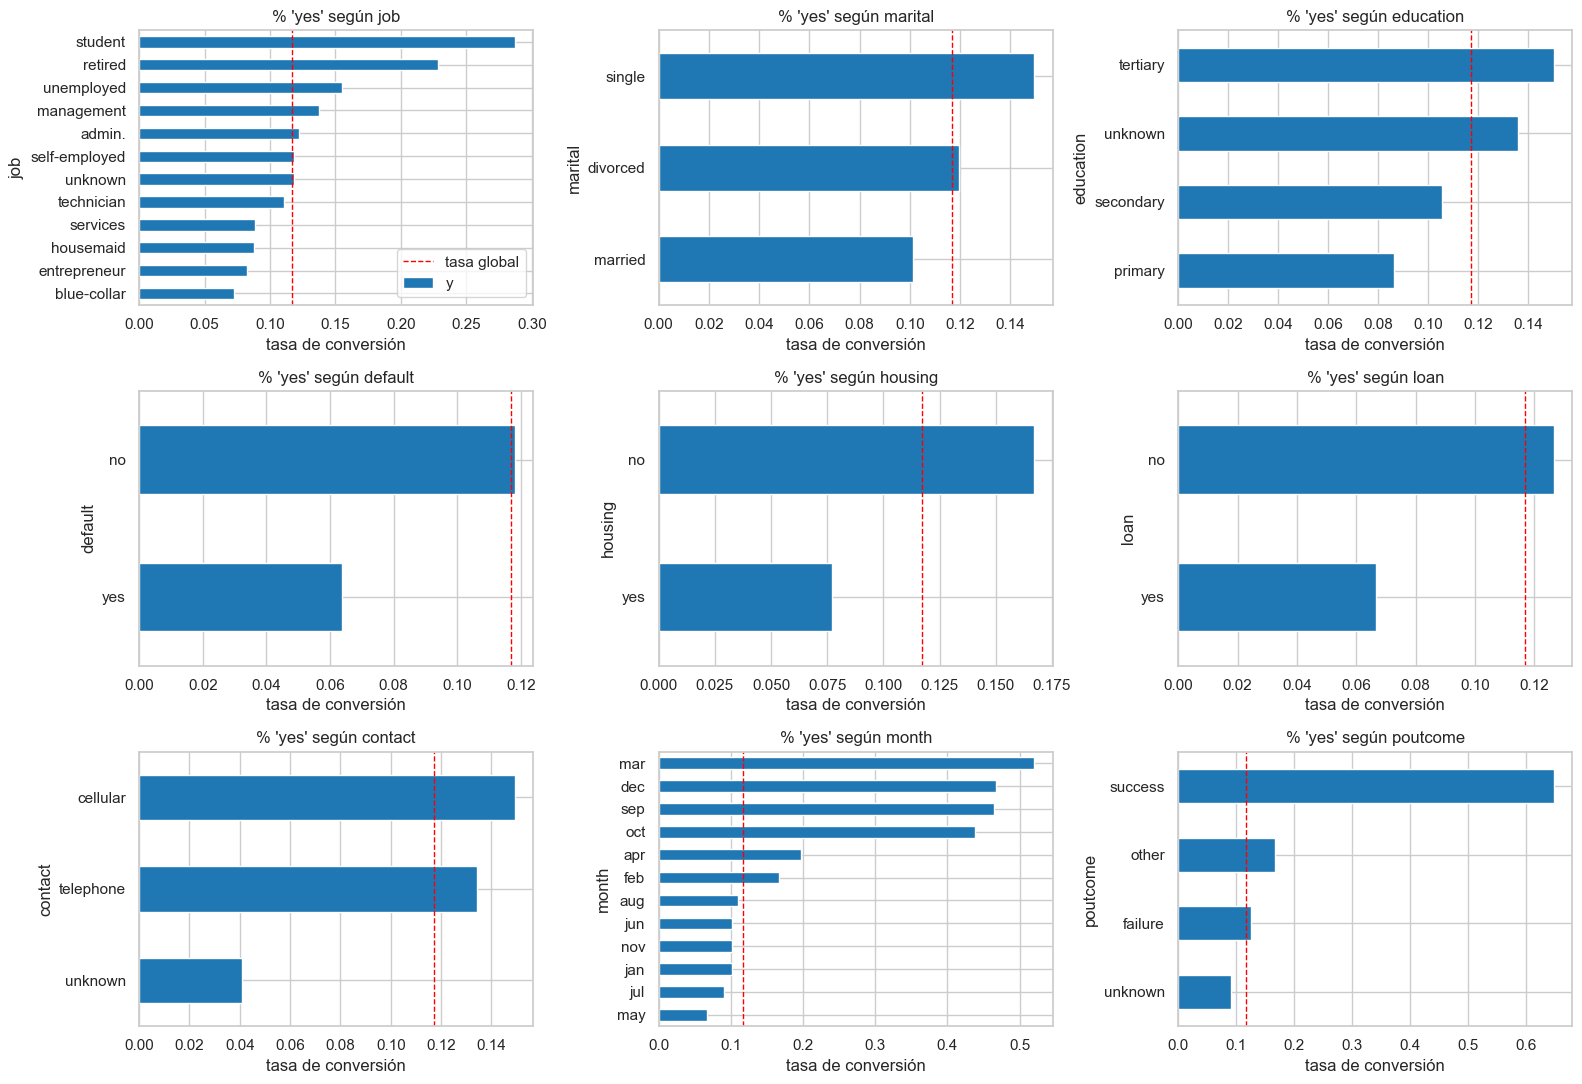

In [9]:
fig, axes = plt.subplots(3, 3, figsize=(16, 11))
tasa_global = (df["y"] == "yes").mean()
for ax, col in zip(axes.ravel(), categoricas_raw):
    tasa = df.groupby(col)["y"].apply(lambda s: (s == "yes").mean()).sort_values()
    tasa.plot(kind="barh", ax=ax, color="tab:blue")
    ax.axvline(tasa_global, color="red", ls="--", lw=1, label="tasa global")
    ax.set_title(f"% 'yes' según {col}"); ax.set_xlabel("tasa de conversión")
axes.ravel()[0].legend()
plt.tight_layout(); plt.show()

**Hallazgo:** las categorías tienen tasas de conversión muy distintas (p. ej. `poutcome=success` ≈ 65 %, estudiantes y jubilados por sobre la media, meses `mar`, `sep`, `oct`, `dec` muy altos). Son **variables nominales sin orden natural** (excepto `education`, cuyo orden es débil y con `unknown`), por lo que se codifican con **One-Hot Encoding**: asignarles enteros (Label Encoding) le impondría a la red un orden y una distancia ficticios.

### 3.5 La variable `duration` (fuga de información)

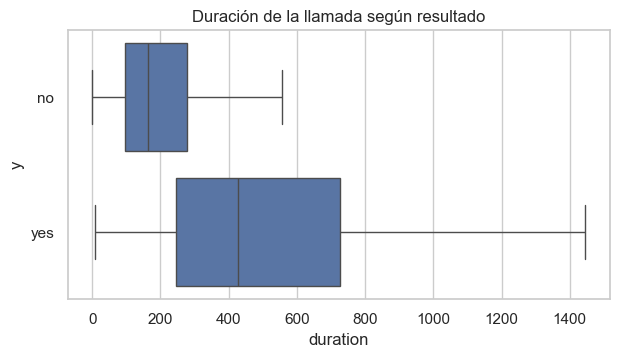

Casos con duration = 0: 3 | de ellos 'yes': 0


In [10]:
fig, ax = plt.subplots(figsize=(7, 3.5))
sns.boxplot(data=df, x="duration", y="y", ax=ax, showfliers=False)
ax.set_title("Duración de la llamada según resultado")
plt.show()
print("Casos con duration = 0:", (df.duration == 0).sum(),
      "| de ellos 'yes':", ((df.duration == 0) & (df.y == "yes")).sum())

**Decisión: se EXCLUYE `duration`.** La duración sólo se conoce **después** de realizar la llamada, y la llamada termina justamente cuando el cliente acepta o rechaza. Un modelo que la use obtiene métricas infladas, pero **no sirve para el objetivo real del banco**: decidir *a quién llamar antes de llamar*. Los autores del dataset (Moro et al., 2014) recomiendan descartarla para un modelo predictivo realista. En la sección 14 cuantificamos cuánto "infla" esta variable las métricas, para dejar evidencia de la decisión.

## 4. Preprocesamiento

Resumen de decisiones (cada una motivada por el EDA):

| Paso | Qué se hace | Por qué |
|---|---|---|
| 1 | Eliminar `duration` | Fuga de información; no disponible antes de llamar |
| 2 | `y` → 1/0 | La red y la pérdida trabajan con números |
| 3 | `contactado_antes = (pdays != -1)` y `pdays=-1 → 0` | `-1` es un código, no una cantidad |
| 4 | `sign(x)·log(1+|x|)` en `balance`, `campaign`, `pdays`, `previous` | Reducir asimetría y efecto de outliers |
| 5 | Partición **estratificada** 70 / 15 / 15 (train / val / test) | Mantener ~11,7 % de positivos en cada conjunto; val para decidir, test sólo al final |
| 6 | `StandardScaler` en numéricas (ajustado **sólo en train**) | Variables en escalas comparables → gradientes balanceados y convergencia más rápida; evitar *data leakage* |
| 7 | `OneHotEncoder(handle_unknown="ignore")` en categóricas (ajustado sólo en train) | Variables nominales sin orden; `unknown` queda como categoría |
| 8 | Conversión a tensores `float32` | Formato que consume PyTorch |

**¿Por qué tres conjuntos?** *Train* para ajustar los pesos; *validación* para comparar configuraciones, hacer *early stopping* y elegir el umbral; *test* se usa **una sola vez**, al final, para obtener una estimación honesta del desempeño en datos nunca vistos.

In [11]:
COLS_LOG = ["balance", "campaign", "pdays", "previous"]

def transformar_crudo(data: pd.DataFrame) -> pd.DataFrame:
    """Transformaciones fila a fila (no aprenden nada de los datos -> no hay fuga)."""
    d = data.drop(columns=["duration"]).copy()
    d["contactado_antes"] = (d["pdays"] != -1).astype(int)
    d.loc[d["pdays"] == -1, "pdays"] = 0
    for c in COLS_LOG:
        d[c] = np.sign(d[c]) * np.log1p(np.abs(d[c]))
    return d

datos = transformar_crudo(df)
y_all = (datos.pop("y") == "yes").astype(np.float32).values
X_all = datos

COLS_NUM = ["age", "balance", "day", "campaign", "pdays", "previous"]
COLS_BIN = ["contactado_antes"]
COLS_CAT = ["job", "marital", "education", "default", "housing", "loan", "contact", "month", "poutcome"]

# Partición estratificada 70/15/15
X_tmp, X_test_df, y_tmp, y_test = train_test_split(X_all, y_all, test_size=0.15,
                                                   stratify=y_all, random_state=SEED)
X_train_df, X_val_df, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.15/0.85,
                                                        stratify=y_tmp, random_state=SEED)

pd.DataFrame({"filas": [len(y_train), len(y_val), len(y_test)],
              "% positivos": [y_train.mean()*100, y_val.mean()*100, y_test.mean()*100]},
             index=["train", "val", "test"]).round(2)

,filas,% positivos
train,31647,11.7000
val,6782,11.6900
test,6782,11.6900


In [12]:
def crear_preprocesador():
    return ColumnTransformer([
        ("num", StandardScaler(), COLS_NUM),
        ("bin", "passthrough", COLS_BIN),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), COLS_CAT),
    ])

prep = crear_preprocesador()
X_train = prep.fit_transform(X_train_df).astype(np.float32)   # fit SOLO con train
X_val   = prep.transform(X_val_df).astype(np.float32)
X_test  = prep.transform(X_test_df).astype(np.float32)
NOMBRES_FEAT = prep.get_feature_names_out()
N_FEAT = X_train.shape[1]

print("Dimensión de entrada de la red:", N_FEAT, "variables")
print("Medias numéricas en train (≈0):", X_train[:, :len(COLS_NUM)].mean(0).round(3))
print("Desv. estándar en train   (≈1):", X_train[:, :len(COLS_NUM)].std(0).round(3))
pd.DataFrame(X_train[:5], columns=NOMBRES_FEAT).iloc[:, :14]

Dimensión de entrada de la red: 51 variables
Medias numéricas en train (≈0): [-0. -0. -0. -0. -0.  0.]
Desv. estándar en train   (≈1): [1. 1. 1. 1. 1. 1.]


,num__age,num__balance,num__day,num__campaign,num__pdays,num__previous,bin__contactado_antes,cat__job_admin.,cat__job_blue-collar,cat__job_entrepreneur,cat__job_housemaid,cat__job_management,cat__job_retired,cat__job_self-employed
0,-0.4644,0.2857,0.2607,-0.9091,-0.4665,-0.4238,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000
1,0.1931,0.5265,1.2236,-0.9091,-0.4665,-0.4238,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
2,-0.9341,-0.9893,-1.0633,-0.9091,-0.4665,-0.4238,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000
3,1.6021,0.7818,-0.4615,1.2366,-0.4665,-0.4238,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000
4,0.8506,0.3287,-0.1004,4.5661,-0.4665,-0.4238,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000


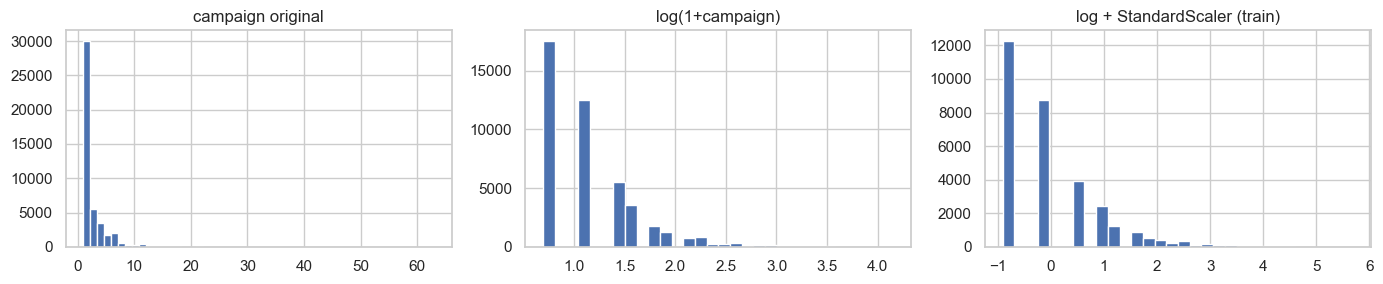

pos_weight (neg/pos en train) = 7.55


In [13]:
# Efecto de la transformación log + estandarización sobre una variable asimétrica
fig, axes = plt.subplots(1, 3, figsize=(14, 3))
axes[0].hist(df["campaign"], bins=50); axes[0].set_title("campaign original")
axes[1].hist(np.log1p(df["campaign"]), bins=30); axes[1].set_title("log(1+campaign)")
axes[2].hist(X_train[:, COLS_NUM.index("campaign")], bins=30); axes[2].set_title("log + StandardScaler (train)")
plt.tight_layout(); plt.show()

# Tensores para PyTorch
to_t = lambda a: torch.tensor(a, dtype=torch.float32, device=DEVICE)
Xtr_t, ytr_t = to_t(X_train), to_t(y_train)
Xva_t, yva_t = to_t(X_val), to_t(y_val)
Xte_t, yte_t = to_t(X_test), to_t(y_test)
POS_WEIGHT = float((1 - y_train.mean()) / y_train.mean())
print(f"pos_weight (neg/pos en train) = {POS_WEIGHT:.2f}")

## 5. Fundamentos: funciones de activación, error y salida programadas desde cero

Antes de usar PyTorch implementamos a mano (NumPy) las funciones que componen una red neuronal, junto con sus **derivadas**, porque es la derivada la que determina cómo fluye el gradiente durante el *backpropagation* y, por lo tanto, la **velocidad de convergencia**.

| Función | Fórmula | Derivada | Rango | Comentario |
|---|---|---|---|---|
| Sigmoide | $\sigma(z)=\frac{1}{1+e^{-z}}$ | $\sigma(z)(1-\sigma(z))$ | (0, 1) | Derivada máx. 0,25 → **desvanecimiento del gradiente** en capas ocultas. Ideal como **salida** binaria (probabilidad). |
| Tanh | $\tanh(z)$ | $1-\tanh^2(z)$ | (-1, 1) | Centrada en 0 (mejor que sigmoide), pero también se satura. |
| ReLU | $\max(0,z)$ | $1$ si $z>0$, si no $0$ | [0, ∞) | No se satura para $z>0$ → gradiente estable, barata. Riesgo de "neuronas muertas". |
| Leaky ReLU | $\max(\alpha z, z)$ | $1$ ó $\alpha$ | (-∞, ∞) | Evita neuronas muertas. |
| ELU | $z$ si $z>0$, si no $\alpha(e^z-1)$ | $1$ ó $\alpha e^z$ | (-α, ∞) | Suave, salidas con media cercana a 0. |
| Softmax | $\frac{e^{z_k}}{\sum_j e^{z_j}}$ | — | (0,1), suma 1 | Salida multiclase; con 2 clases equivale a la sigmoide. |

**Funciones de error (pérdida)** para clasificación binaria, con $p=\sigma(z)$:
- **Entropía cruzada binaria (BCE):** $L=-[y\log p+(1-y)\log(1-p)]$. Es la pérdida de máxima verosimilitud para una salida Bernoulli; combinada con sigmoide su gradiente respecto al logit es simplemente $p-y$ (no se satura).
- **BCE ponderada:** multiplica el término positivo por $w_+=\frac{N_{neg}}{N_{pos}}$ para compensar el desbalance.
- **Focal loss:** $L=-\alpha(1-p_t)^\gamma\log p_t$; reduce el peso de los ejemplos fáciles y concentra el aprendizaje en los difíciles.
- **MSE:** $L=(y-p)^2$; pensada para regresión. Con sigmoide, su gradiente $2(p-y)\,p(1-p)$ se anula cuando la neurona se satura, aunque esté **equivocada**.

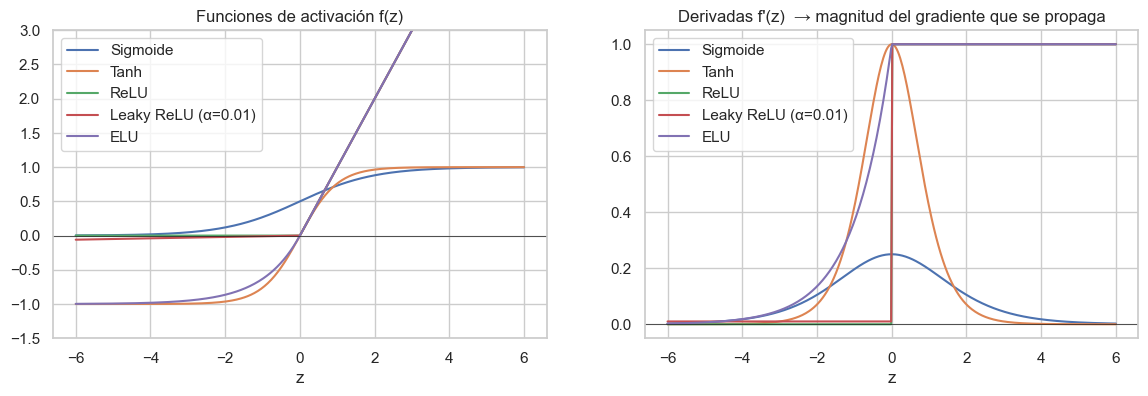

In [14]:
# ---------- Funciones de activación y sus derivadas (NumPy) ----------
def sigmoid(z):        return 1 / (1 + np.exp(-z))
def d_sigmoid(z):      s = sigmoid(z); return s * (1 - s)
def tanh(z):           return np.tanh(z)
def d_tanh(z):         return 1 - np.tanh(z) ** 2
def relu(z):           return np.maximum(0, z)
def d_relu(z):         return (z > 0).astype(float)
def leaky_relu(z, a=0.01):   return np.where(z > 0, z, a * z)
def d_leaky_relu(z, a=0.01): return np.where(z > 0, 1.0, a)
def elu(z, a=1.0):     return np.where(z > 0, z, a * (np.exp(z) - 1))
def d_elu(z, a=1.0):   return np.where(z > 0, 1.0, a * np.exp(z))
def softmax(Z):
    Z = Z - Z.max(axis=1, keepdims=True)           # estabilidad numérica
    e = np.exp(Z); return e / e.sum(axis=1, keepdims=True)

# ---------- Funciones de error ----------
EPS = 1e-7
def bce(y, p):                 p = np.clip(p, EPS, 1-EPS); return -np.mean(y*np.log(p) + (1-y)*np.log(1-p))
def bce_ponderada(y, p, w):    p = np.clip(p, EPS, 1-EPS); return -np.mean(w*y*np.log(p) + (1-y)*np.log(1-p))
def mse(y, p):                 return np.mean((y - p) ** 2)
def focal(y, p, alpha=0.25, gamma=2.0):
    p = np.clip(p, EPS, 1-EPS); pt = np.where(y == 1, p, 1-p); at = np.where(y == 1, alpha, 1-alpha)
    return np.mean(-at * (1 - pt) ** gamma * np.log(pt))

z = np.linspace(-6, 6, 400)
acts = {"Sigmoide": (sigmoid, d_sigmoid), "Tanh": (tanh, d_tanh), "ReLU": (relu, d_relu),
        "Leaky ReLU (α=0.01)": (leaky_relu, d_leaky_relu), "ELU": (elu, d_elu)}
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for nombre, (f, df_) in acts.items():
    axes[0].plot(z, f(z), label=nombre); axes[1].plot(z, df_(z), label=nombre)
axes[0].set_title("Funciones de activación f(z)"); axes[0].set_ylim(-1.5, 3)
axes[1].set_title("Derivadas f'(z)  → magnitud del gradiente que se propaga")
for ax in axes: ax.legend(); ax.axhline(0, c="k", lw=.5); ax.set_xlabel("z")
plt.show()

In [15]:
# ---------- Verificación contra PyTorch (validación de la implementación) ----------
zt = torch.tensor(z, requires_grad=True)
verif = {}
for nombre, (f, df_), ft in zip(acts, acts.values(),
        [torch.sigmoid, torch.tanh, torch.relu, lambda x: nn.functional.leaky_relu(x, 0.01), nn.functional.elu]):
    zt.grad = None
    out = ft(zt); out.sum().backward()
    verif[nombre] = {"error máx. f(z)": np.abs(out.detach().numpy() - f(z)).max(),
                     "error máx. f'(z)": np.abs(zt.grad.numpy() - df_(z)).max()}

y_ej = np.array([1, 0, 1, 0, 1.]); p_ej = np.array([.9, .2, .3, .6, .99])
pt_, yt_ = torch.tensor(p_ej), torch.tensor(y_ej)
verif["BCE"] = {"error máx. f(z)": abs(bce(y_ej, p_ej) - nn.functional.binary_cross_entropy(pt_, yt_).item()), "error máx. f'(z)": np.nan}
verif["MSE"] = {"error máx. f(z)": abs(mse(y_ej, p_ej) - nn.functional.mse_loss(pt_, yt_).item()), "error máx. f'(z)": np.nan}
Z2 = np.random.randn(4, 2)
verif["Softmax(2) vs Sigmoide"] = {"error máx. f(z)": np.abs(softmax(Z2)[:, 1] - sigmoid(Z2[:, 1] - Z2[:, 0])).max(), "error máx. f'(z)": np.nan}
pd.DataFrame(verif).T

,error máx. f(z),error máx. f'(z)
Sigmoide,0.0000,0.0000
Tanh,0.0000,0.0000
ReLU,0.0000,0.0000
Leaky ReLU (α=0.01),0.0000,0.0000
ELU,0.0000,0.0000
BCE,0.0000,NaN
MSE,0.0000,NaN
Softmax(2) vs Sigmoide,0.0000,NaN


Las diferencias son del orden de $10^{-16}$ (precisión de máquina): **las implementaciones propias coinciden con PyTorch**. La última fila demuestra que **softmax con 2 salidas es equivalente a una sigmoide** sobre la diferencia de logits; por eso, para este problema binario, usamos **una única neurona de salida con sigmoide** (menos parámetros, mismo resultado).

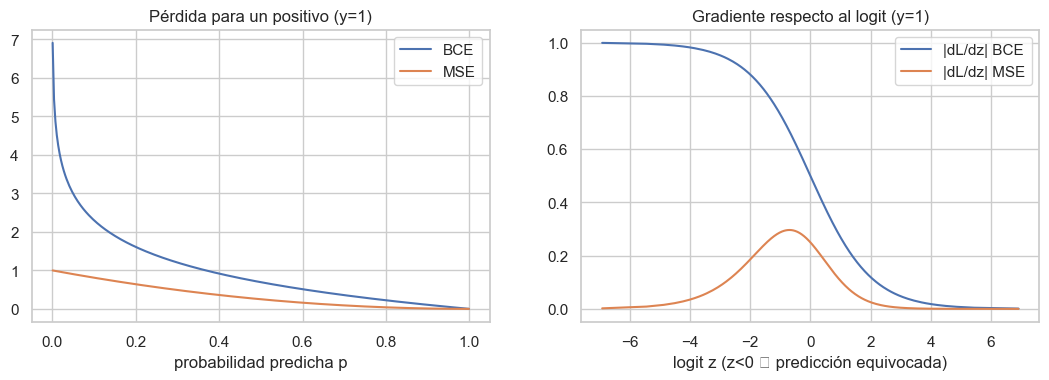

In [16]:
# ---------- ¿Por qué BCE y no MSE con salida sigmoide? ----------
p = np.linspace(0.001, 0.999, 300)          # predicción para un ejemplo con y = 1
zz = np.log(p / (1 - p))                    # logit correspondiente
grad_bce = p - 1                            # dL/dz de BCE + sigmoide
grad_mse = 2 * (p - 1) * p * (1 - p)        # dL/dz de MSE + sigmoide
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].plot(p, -np.log(p), label="BCE"); axes[0].plot(p, (1 - p) ** 2, label="MSE")
axes[0].set(title="Pérdida para un positivo (y=1)", xlabel="probabilidad predicha p"); axes[0].legend()
axes[1].plot(zz, np.abs(grad_bce), label="|dL/dz| BCE"); axes[1].plot(zz, np.abs(grad_mse), label="|dL/dz| MSE")
axes[1].set(title="Gradiente respecto al logit (y=1)", xlabel="logit z (z<0 ⇒ predicción equivocada)"); axes[1].legend()
plt.show()

**Interpretación:** cuando la red se equivoca con mucha confianza (logit muy negativo para un positivo), **BCE entrega el gradiente máximo** (≈1) y corrige rápido, mientras que **MSE entrega un gradiente casi nulo**: la neurona saturada "no aprende de sus errores". Esto anticipa que MSE convergerá peor (se verifica experimentalmente en la sección 9).

### 5.1 Perceptrón implementado desde cero

Como punto de partida conceptual, entrenamos un **perceptrón** (una sola neurona con salida sigmoide = regresión logística) con descenso del gradiente programado a mano. Su gradiente es $\nabla_w L = \frac{1}{N}X^\top(\sigma(Xw+b)-y)$. Este modelo **lineal** es la línea base que el MLP debe superar gracias a sus capas ocultas no lineales.

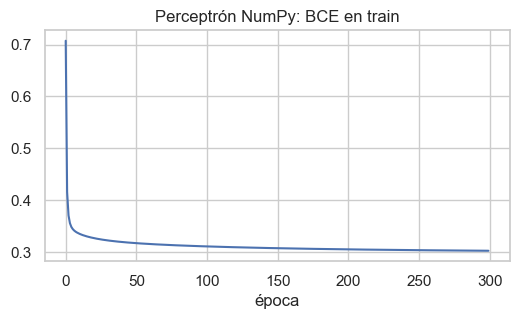

Perceptrón (val) -> PR-AUC = 0.4010 | ROC-AUC = 0.7635 | F1@0.5 = 0.2453


In [17]:
def entrenar_perceptron(X, y, lr=0.5, epocas=300):
    rng = np.random.default_rng(SEED)
    w = rng.normal(0, 0.01, X.shape[1]); b = 0.0; hist = []
    for _ in range(epocas):
        p = sigmoid(X @ w + b)                  # forward
        hist.append(bce(y, p))                  # error
        g = p - y                               # dL/dz (BCE + sigmoide)
        w -= lr * X.T @ g / len(y)              # backward + actualización
        b -= lr * g.mean()
    return w, b, hist

w_p, b_p, hist_p = entrenar_perceptron(X_train, y_train)
p_val_perc = sigmoid(X_val @ w_p + b_p)
plt.figure(figsize=(6, 3)); plt.plot(hist_p); plt.title("Perceptrón NumPy: BCE en train"); plt.xlabel("época"); plt.show()
print(f"Perceptrón (val) -> PR-AUC = {average_precision_score(y_val, p_val_perc):.4f} | "
      f"ROC-AUC = {roc_auc_score(y_val, p_val_perc):.4f} | F1@0.5 = {f1_score(y_val, p_val_perc >= .5):.4f}")

## 6. Definición del modelo MLP en PyTorch

Arquitectura parametrizable para poder realizar experimentos controlados:

```
Entrada (N_FEAT) → [Linear → (BatchNorm) → Activación → (Dropout)] × k capas ocultas → Linear(1) → logit
```

Decisiones técnicas:
- **Capa de salida: 1 neurona sin activación (logit).** La sigmoide se aplica dentro de `BCEWithLogitsLoss`, que usa el truco *log-sum-exp* y es numéricamente más estable que `Sigmoid` + `BCELoss`. Para predecir se usa `p = sigmoid(logit)`.
- **Inicialización He (Kaiming)** para ReLU y variantes, y **Xavier (Glorot)** para tanh/sigmoide: mantienen la varianza de las activaciones entre capas y evitan que el gradiente explote o se desvanezca al inicio.
- **BatchNorm antes de la activación** (como en Ioffe & Szegedy, 2015) y **Dropout después** de la activación.
- **Optimizador Adam** por defecto (tasa de aprendizaje adaptativa por parámetro; robusto con features One-Hot dispersas).

In [18]:
ACTIVACIONES = {"relu": nn.ReLU, "leaky_relu": lambda: nn.LeakyReLU(0.01), "elu": nn.ELU,
                "tanh": nn.Tanh, "sigmoid": nn.Sigmoid}

class MLP(nn.Module):
    """Perceptrón multicapa para clasificación binaria (devuelve logits)."""
    def __init__(self, n_in, capas=(64, 32), activacion="relu", dropout=0.0, batchnorm=False):
        super().__init__()
        bloques, prev = [], n_in
        for h in capas:
            bloques.append(nn.Linear(prev, h))
            if batchnorm: bloques.append(nn.BatchNorm1d(h))
            bloques.append(ACTIVACIONES[activacion]())
            if dropout > 0: bloques.append(nn.Dropout(dropout))
            prev = h
        self.ocultas = nn.Sequential(*bloques)
        self.salida = nn.Linear(prev, 1)
        self._inicializar(activacion)

    def _inicializar(self, activacion):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                if activacion in ("tanh", "sigmoid"): nn.init.xavier_uniform_(m.weight)
                else: nn.init.kaiming_uniform_(m.weight, nonlinearity="relu")
                nn.init.zeros_(m.bias)

    def forward(self, x):
        return self.salida(self.ocultas(x)).squeeze(-1)

print(MLP(N_FEAT))
print("Parámetros entrenables:", sum(p.numel() for p in MLP(N_FEAT).parameters()))

MLP(
  (ocultas): Sequential(
    (0): Linear(in_features=51, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
  )
  (salida): Linear(in_features=32, out_features=1, bias=True)
)
Parámetros entrenables: 5441


### 6.1 Funciones de pérdida y bucle de entrenamiento

Se implementan las cuatro pérdidas a comparar. La función `entrenar` recibe un diccionario de configuración, de modo que cada experimento cambia **sólo** la clave que se estudia y hereda el resto de `CFG_BASE`.

In [19]:
class FocalLoss(nn.Module):
    """Focal loss (Lin et al., 2017) para clasificación binaria a partir de logits."""
    def __init__(self, alpha=0.75, gamma=2.0):
        super().__init__(); self.alpha, self.gamma = alpha, gamma
    def forward(self, logits, y):
        bce_ = nn.functional.binary_cross_entropy_with_logits(logits, y, reduction="none")
        p = torch.sigmoid(logits)
        pt = y * p + (1 - y) * (1 - p)
        at = y * self.alpha + (1 - y) * (1 - self.alpha)
        return (at * (1 - pt) ** self.gamma * bce_).mean()

class MSESigmoide(nn.Module):
    """Error cuadrático medio sobre la probabilidad (sigmoide del logit)."""
    def forward(self, logits, y): return ((torch.sigmoid(logits) - y) ** 2).mean()

def crear_perdida(nombre):
    if nombre == "bce":           return nn.BCEWithLogitsLoss()
    if nombre == "bce_ponderada": return nn.BCEWithLogitsLoss(pos_weight=torch.tensor(POS_WEIGHT, device=DEVICE))
    if nombre == "focal":         return FocalLoss()
    if nombre == "mse":           return MSESigmoide()
    raise ValueError(nombre)

def crear_optimizador(nombre, params, lr, l2):
    if nombre == "adam":         return torch.optim.Adam(params, lr=lr, weight_decay=l2)
    if nombre == "adamw":        return torch.optim.AdamW(params, lr=lr, weight_decay=l2)
    if nombre == "sgd":          return torch.optim.SGD(params, lr=lr, weight_decay=l2)
    if nombre == "sgd_momentum": return torch.optim.SGD(params, lr=lr, momentum=0.9, nesterov=True, weight_decay=l2)
    if nombre == "rmsprop":      return torch.optim.RMSprop(params, lr=lr, weight_decay=l2)
    raise ValueError(nombre)

CFG_BASE = dict(capas=(64, 32), activacion="relu", dropout=0.0, batchnorm=False,
                perdida="bce", optimizador="adam", lr=1e-3, l2=0.0,
                batch_size=256, epocas=40, paciencia=None, scheduler=False, seed=SEED)

@torch.no_grad()
def predecir_proba(modelo, X, bs=8192):
    modelo.eval()
    return torch.cat([torch.sigmoid(modelo(X[i:i+bs])) for i in range(0, len(X), bs)]).cpu().numpy()

def metricas(y, p, umbral=0.5):
    pred = (p >= umbral).astype(int)
    return {"accuracy": accuracy_score(y, pred), "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred), "f1": f1_score(y, pred),
            "roc_auc": roc_auc_score(y, p), "pr_auc": average_precision_score(y, p)}

def entrenar(cfg=None, X=None, y=None, Xv=None, yv=None, **kw):
    """Entrena un MLP. Devuelve (modelo, historial, métricas en validación, segundos)."""
    cfg = {**CFG_BASE, **(cfg or {}), **kw}
    X, y = (Xtr_t, ytr_t) if X is None else (X, y)
    Xv, yv = (Xva_t, yva_t) if Xv is None else (Xv, yv)
    fijar_semilla(cfg["seed"])
    modelo = MLP(X.shape[1], cfg["capas"], cfg["activacion"], cfg["dropout"], cfg["batchnorm"]).to(DEVICE)
    opt = crear_optimizador(cfg["optimizador"], modelo.parameters(), cfg["lr"], cfg["l2"])
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=3) if cfg["scheduler"] else None
    loss_fn = crear_perdida(cfg["perdida"])
    hist = {k: [] for k in ["train_loss", "val_loss", "val_pr_auc", "val_f1", "lr"]}
    mejor, mejor_estado, sin_mejora = np.inf, None, 0
    t0, n = time.time(), len(X)
    for ep in range(cfg["epocas"]):
        modelo.train(); perm = torch.randperm(n, device=DEVICE); acum = 0.0
        for i in range(0, n, cfg["batch_size"]):
            idx = perm[i:i + cfg["batch_size"]]
            if len(idx) < 2: continue                       # BatchNorm necesita >1 muestra
            opt.zero_grad()
            loss = loss_fn(modelo(X[idx]), y[idx])
            loss.backward(); opt.step()
            acum += loss.item() * len(idx)
        modelo.eval()
        with torch.no_grad():
            val_loss = loss_fn(modelo(Xv), yv).item()
        p_v = predecir_proba(modelo, Xv); yv_np = yv.cpu().numpy()
        hist["train_loss"].append(acum / n); hist["val_loss"].append(val_loss)
        hist["val_pr_auc"].append(average_precision_score(yv_np, p_v))
        hist["val_f1"].append(f1_score(yv_np, p_v >= 0.5)); hist["lr"].append(opt.param_groups[0]["lr"])
        if sched: sched.step(val_loss)
        if cfg["paciencia"]:                                # early stopping sobre la pérdida de validación
            if val_loss < mejor - 1e-5:
                mejor, sin_mejora = val_loss, 0
                mejor_estado = {k: v.clone() for k, v in modelo.state_dict().items()}
            else:
                sin_mejora += 1
                if sin_mejora >= cfg["paciencia"]: break
    if mejor_estado is not None: modelo.load_state_dict(mejor_estado)
    seg = time.time() - t0
    res = metricas(yv.cpu().numpy(), predecir_proba(modelo, Xv))
    res["épocas"] = len(hist["train_loss"]); res["seg"] = seg
    return modelo, hist, res, seg

def experimento(nombre_param, valores, base=None, **fijos):
    """Varía UN parámetro manteniendo el resto fijo. Devuelve tabla e historiales."""
    filas, hists = {}, {}
    for v in valores:
        _, h, r, _ = entrenar(base, **{**fijos, nombre_param: v})
        # métricas "en el mejor punto": separan la velocidad de convergencia de la calidad alcanzable
        r["val_loss mín"] = min(h["val_loss"]); r["época val_loss mín"] = int(np.argmin(h["val_loss"])) + 1
        r["PR-AUC máx"] = max(h["val_pr_auc"]); r["época PR-AUC máx"] = int(np.argmax(h["val_pr_auc"])) + 1
        etiqueta = f"{nombre_param}={v}"
        filas[etiqueta], hists[etiqueta] = r, h
        print(f"{etiqueta:<26} PR-AUC final={r['pr_auc']:.4f} | PR-AUC máx={r['PR-AUC máx']:.4f} "
              f"(época {r['época PR-AUC máx']}) | {r['seg']:.1f}s")
    return pd.DataFrame(filas).T, hists

def graficar_historias(hists, titulo, claves=("train_loss", "val_loss", "val_pr_auc"), ylim_loss=None):
    nombres = {"train_loss": "Pérdida en entrenamiento", "val_loss": "Pérdida en validación",
               "val_pr_auc": "PR-AUC en validación", "val_f1": "F1 en validación (umbral 0.5)"}
    fig, axes = plt.subplots(1, len(claves), figsize=(6 * len(claves), 4))
    for ax, k in zip(np.atleast_1d(axes), claves):
        for et, h in hists.items(): ax.plot(h[k], label=et)
        ax.set_title(nombres[k]); ax.set_xlabel("época")
        if ylim_loss and "loss" in k: ax.set_ylim(*ylim_loss)
    np.atleast_1d(axes)[0].legend(fontsize=8)
    fig.suptitle(titulo, fontsize=13, y=1.02); plt.tight_layout(); plt.show()

def resaltar(tabla, cols_max=("accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "PR-AUC máx")):
    """Tabla con formato: verde = mejor valor de cada métrica."""
    cols = [c for c in cols_max if c in tabla.columns]
    st = tabla.style.format("{:.4f}", subset=cols).format("{:.1f}", subset=["seg"]) \
              .format("{:.0f}", subset=[c for c in tabla.columns if c.startswith("época")]) \
              .highlight_max(subset=cols, color="#c6efce")
    if "val_loss mín" in tabla.columns:
        st = st.format("{:.4f}", subset=["val_loss mín"]).highlight_min(subset=["val_loss mín"], color="#c6efce")
    return st

## 7. Modelo base y experimentos controlados de entrenamiento

**Modelo base** (punto de partida razonable, siguiendo valores por defecto ampliamente usados):

| Hiperparámetro | Valor base | Justificación inicial |
|---|---|---|
| Capas ocultas | 64 → 32 | Embudo moderado para ~50 entradas; capacidad suficiente sin sobredimensionar |
| Activación | ReLU | Estándar en capas ocultas, no se satura |
| Pérdida | BCE | Pérdida natural para salida binaria |
| Optimizador | Adam, lr = 0.001 | Valor por defecto recomendado por Kingma & Ba (2015) |
| Batch size | 256 | Compromiso entre estabilidad del gradiente y velocidad con ~31 mil filas |
| Épocas | 40 | Se revisa en el experimento 7.1 |

**Metodología de los experimentos controlados:** se varía **un solo parámetro a la vez**, con la **misma semilla** y los **mismos datos**, sin *early stopping* (para ver la curva completa). Se compara con la **pérdida de validación** (convergencia/sobreajuste) y el **PR-AUC de validación** (calidad del ranking de clientes, independiente del umbral).

Cada tabla reporta dos tipos de métricas, porque un número fijo de épocas favorece injustamente a las configuraciones lentas (todavía no alcanzan a sobreajustar):
- **Métricas al final** (`accuracy` … `pr_auc`): cómo queda el modelo tras las 40 épocas → mide la **estabilidad** frente al sobreajuste.
- **Métricas en el mejor punto** (`val_loss mín`, `PR-AUC máx` y la **época** en que ocurren): la calidad máxima que alcanza la configuración y **qué tan rápido converge**.

In [20]:
modelo_base, hist_base, res_base, _ = entrenar()
tabla_global = pd.DataFrame({"Perceptrón (NumPy)": metricas(y_val, p_val_perc), "MLP base": res_base}).T
tabla_global

,accuracy,precision,recall,f1,roc_auc,pr_auc,épocas,seg
Perceptrón (NumPy),0.8930,0.6982,0.1488,0.2453,0.7635,0.4010,NaN,NaN
MLP base,0.8906,0.5684,0.2673,0.3636,0.7824,0.4070,40.0000,10.2043


Con BCE estándar y umbral 0,5 el modelo base tiene buena accuracy pero **recall bajo**: como el 88 % de los ejemplos es negativo, la red aprende a ser conservadora y rara vez predice "yes". Esto se aborda más adelante con la función de pérdida (sección 9) y el umbral (sección 12).

### 7.1 Número de épocas
Entrenamos el modelo base durante **100 épocas** y observamos cuándo la pérdida de validación deja de mejorar.

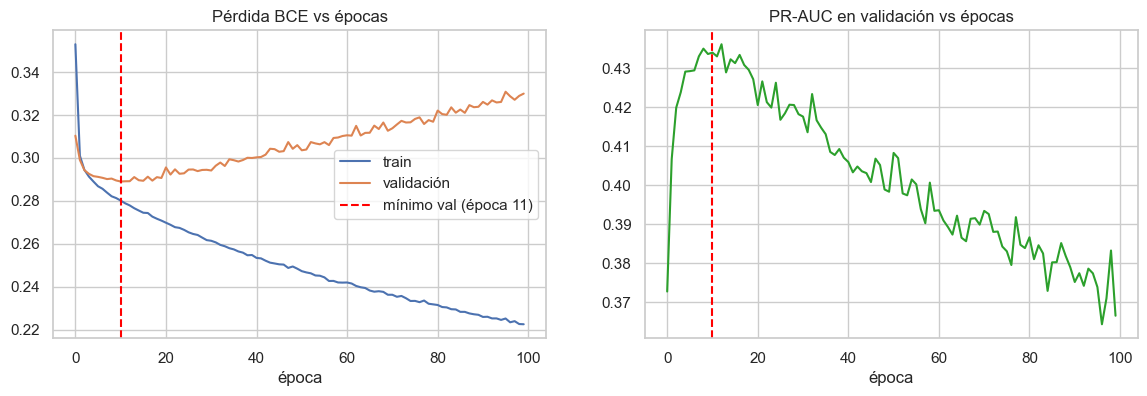

Mínimo de la pérdida de validación en la época 11: 0.2890
Pérdida de validación en la época 100: 0.3299  (train: 0.2226)


In [21]:
_, hist_100, _, _ = entrenar(epocas=100)
ep_opt = int(np.argmin(hist_100["val_loss"])) + 1
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(hist_100["train_loss"], label="train"); axes[0].plot(hist_100["val_loss"], label="validación")
axes[0].axvline(ep_opt - 1, c="red", ls="--", label=f"mínimo val (época {ep_opt})")
axes[0].set(title="Pérdida BCE vs épocas", xlabel="época"); axes[0].legend()
axes[1].plot(hist_100["val_pr_auc"], c="tab:green"); axes[1].axvline(ep_opt - 1, c="red", ls="--")
axes[1].set(title="PR-AUC en validación vs épocas", xlabel="época")
plt.show()
print(f"Mínimo de la pérdida de validación en la época {ep_opt}: {min(hist_100['val_loss']):.4f}")
print(f"Pérdida de validación en la época 100: {hist_100['val_loss'][-1]:.4f}  (train: {hist_100['train_loss'][-1]:.4f})")

**Análisis:** la pérdida de entrenamiento baja de forma monótona, pero la de validación alcanza un mínimo temprano y luego **sube** mientras la brecha train/val crece: el modelo **memoriza** el conjunto de entrenamiento (sobreajuste) y el PR-AUC de validación se deteriora. **Decisión:** en lugar de fijar un número de épocas a mano, se usará **early stopping** (paciencia = 8 épocas sobre la pérdida de validación, restaurando los mejores pesos) con un máximo generoso de épocas. Esto es más robusto porque el punto óptimo cambia con la tasa de aprendizaje, el batch y la regularización.

### 7.2 Tasa de aprendizaje (learning rate)

lr=0.0001                  PR-AUC final=0.4299 | PR-AUC máx=0.4299 (época 40) | 12.7s
lr=0.001                   PR-AUC final=0.4070 | PR-AUC máx=0.4361 (época 13) | 13.4s
lr=0.01                    PR-AUC final=0.3420 | PR-AUC máx=0.4461 (época 8) | 27.8s
lr=0.05                    PR-AUC final=0.3896 | PR-AUC máx=0.4414 (época 5) | 17.0s


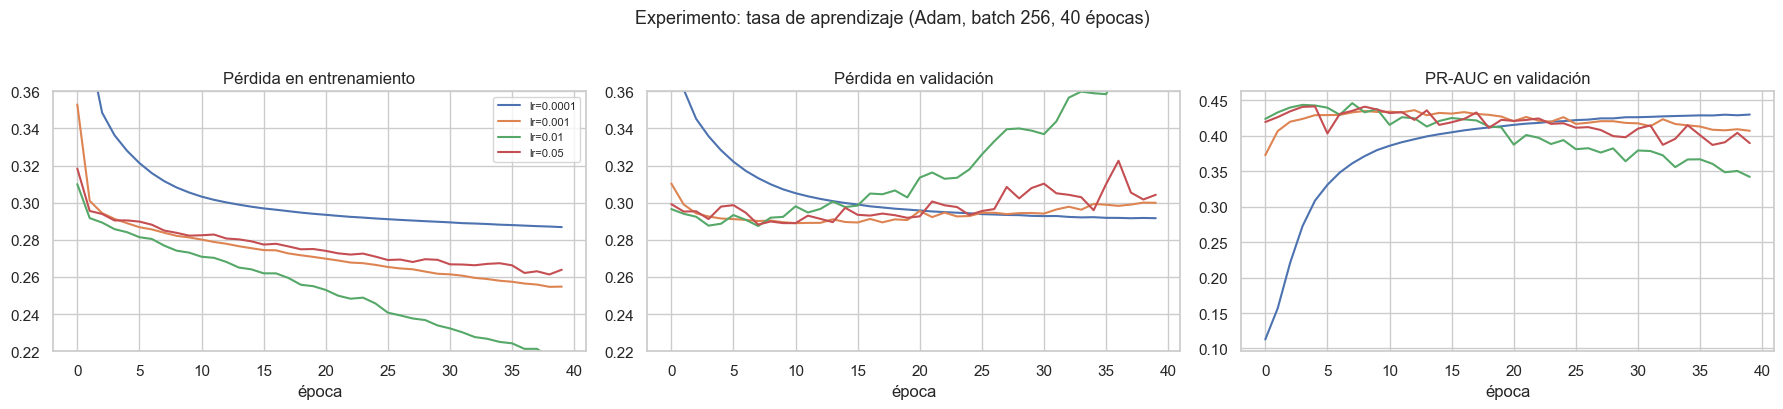

,accuracy,precision,recall,f1,roc_auc,pr_auc,épocas,seg,val_loss mín,época val_loss mín,PR-AUC máx,época PR-AUC máx
lr=0.0001,0.8930,0.6192,0.2194,0.3240,0.7883,0.4299,40,12.7,0.2917,38,0.4299,40
lr=0.001,0.8906,0.5684,0.2673,0.3636,0.7824,0.4070,40,13.4,0.2890,11,0.4361,13
lr=0.01,0.8807,0.4816,0.2636,0.3407,0.7240,0.3420,40,27.8,0.2875,8,0.4461,8
lr=0.05,0.8913,0.6186,0.1841,0.2838,0.7717,0.3896,40,17.0,0.2882,8,0.4414,5


In [22]:
tabla_lr, hist_lr = experimento("lr", [1e-4, 1e-3, 1e-2, 5e-2])
graficar_historias(hist_lr, "Experimento: tasa de aprendizaje (Adam, batch 256, 40 épocas)", ylim_loss=(0.22, 0.36))
resaltar(tabla_lr)

**Análisis (tasa de aprendizaje):**
- **lr = 0.0001:** convergencia **lenta**; tras 40 épocas sigue mejorando (subajuste por falta de pasos). Necesitaría muchas más épocas.
- **lr = 0.001:** converge suavemente y alcanza su mínimo de validación; luego comienza a sobreajustar.
- **lr = 0.01 y 0.05:** el mínimo de validación se alcanza en pocas épocas, pero luego la pérdida de validación **sube rápido y de forma ruidosa**: pasos demasiado grandes → sobreajuste acelerado e inestabilidad.

**Decisión:** `lr = 0.001` (o un valor cercano) ofrece el mejor compromiso entre velocidad y estabilidad. Se complementa con un **scheduler** `ReduceLROnPlateau` en el modelo final (reduce el lr a la mitad cuando la validación se estanca), que permite partir rápido y afinar al final.

### 7.3 Tamaño del batch

batch_size=32              PR-AUC final=0.3929 | PR-AUC máx=0.4467 (época 8) | 96.5s
batch_size=128             PR-AUC final=0.4060 | PR-AUC máx=0.4391 (época 9) | 26.2s
batch_size=512             PR-AUC final=0.4256 | PR-AUC máx=0.4366 (época 18) | 7.9s
batch_size=2048            PR-AUC final=0.4344 | PR-AUC máx=0.4345 (época 38) | 3.4s


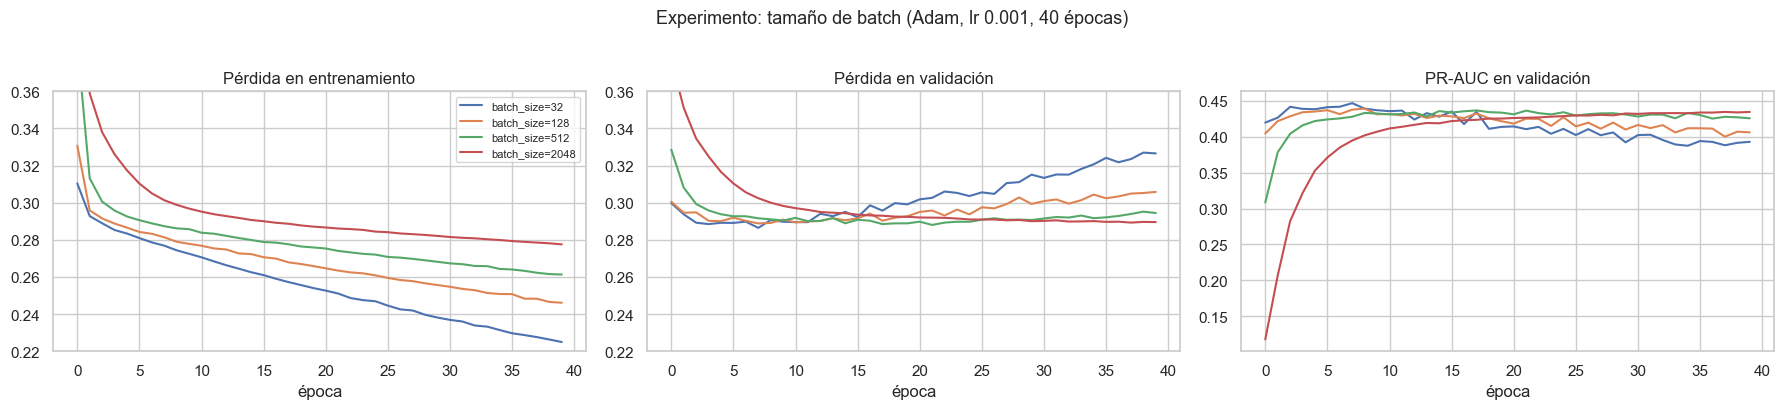

,accuracy,precision,recall,f1,roc_auc,pr_auc,épocas,seg,val_loss mín,época val_loss mín,PR-AUC máx,época PR-AUC máx
batch_size=32,0.8878,0.5315,0.3405,0.4151,0.7674,0.3929,40,96.5,0.2865,8,0.4467,8
batch_size=128,0.8897,0.5591,0.2686,0.3629,0.7775,0.4060,40,26.2,0.2889,8,0.4391,9
batch_size=512,0.8907,0.5596,0.3077,0.3971,0.7882,0.4256,40,7.9,0.2880,22,0.4366,18
batch_size=2048,0.8921,0.5889,0.2547,0.3556,0.7930,0.4344,40,3.4,0.2893,38,0.4345,38


In [23]:
tabla_bs, hist_bs = experimento("batch_size", [32, 128, 512, 2048])
graficar_historias(hist_bs, "Experimento: tamaño de batch (Adam, lr 0.001, 40 épocas)", ylim_loss=(0.22, 0.36))
resaltar(tabla_bs)

**Análisis (batch size):**
- **Batch pequeño (32):** muchas actualizaciones por época → aprende muy rápido pero el gradiente es ruidoso y **sobreajusta antes**; además es el más lento en tiempo de cómputo.
- **Batch muy grande (2048):** pocas actualizaciones por época → convergencia lenta (con 40 épocas aún no llega a su mejor punto), aunque las curvas son muy suaves.
- **128–512:** buen equilibrio entre ruido del gradiente, velocidad y calidad.

**Decisión:** `batch_size = 256` (zona intermedia, uso eficiente de la CPU/GPU). Nótese que **batch y lr interactúan**: un batch más grande suele admitir un lr mayor; por eso los dejamos en valores intermedios y ajustamos su combinación en la sección 11.

## 8. Comparación de funciones de activación (capas ocultas)

Misma arquitectura (64 → 32), mismo optimizador y datos; sólo cambia la activación de las capas ocultas. Para hacer visible el efecto en **profundidad** (desvanecimiento del gradiente) se repite también con una red **más profunda (5 capas de 32)**.

activacion=relu            PR-AUC final=0.4070 | PR-AUC máx=0.4361 (época 13) | 13.2s
activacion=leaky_relu      PR-AUC final=0.4093 | PR-AUC máx=0.4358 (época 15) | 12.6s
activacion=elu             PR-AUC final=0.4387 | PR-AUC máx=0.4535 (época 22) | 13.5s
activacion=tanh            PR-AUC final=0.4546 | PR-AUC máx=0.4624 (época 34) | 14.4s
activacion=sigmoid         PR-AUC final=0.4332 | PR-AUC máx=0.4332 (época 40) | 13.6s


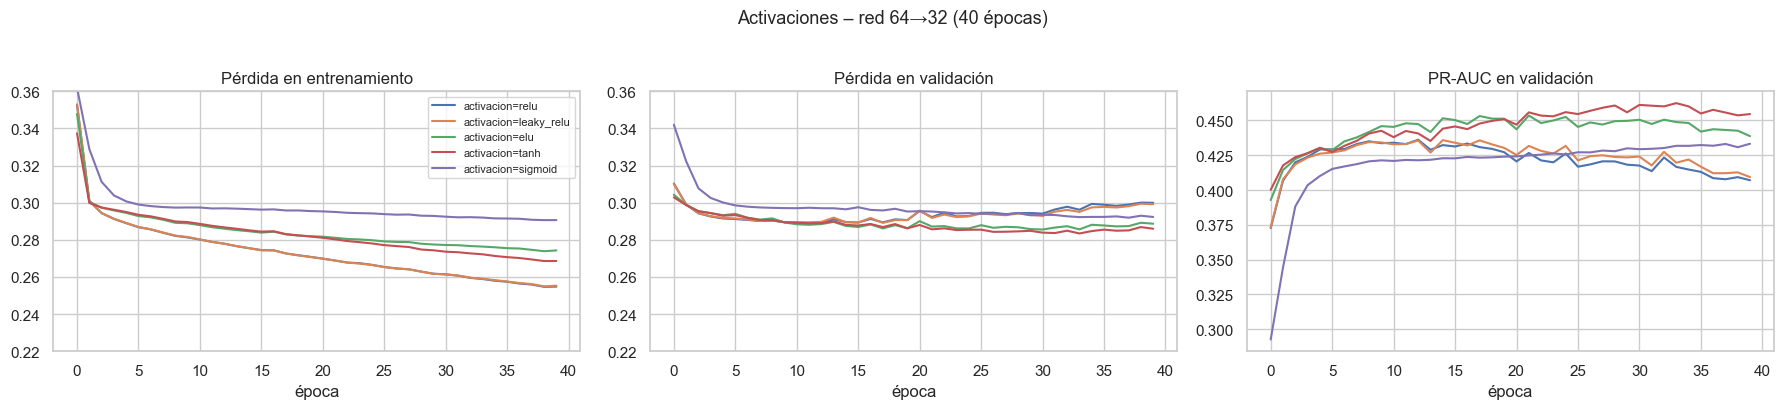

,accuracy,precision,recall,f1,roc_auc,pr_auc,épocas,seg,val_loss mín,época val_loss mín,PR-AUC máx,época PR-AUC máx
activacion=relu,0.8906,0.5684,0.2673,0.3636,0.7824,0.4070,40,13.2,0.2890,11,0.4361,13
activacion=leaky_relu,0.8913,0.5795,0.2573,0.3563,0.7810,0.4093,40,12.6,0.2892,18,0.4358,15
activacion=elu,0.8956,0.6171,0.2825,0.3875,0.7935,0.4387,40,13.5,0.2856,31,0.4535,22
activacion=tanh,0.8962,0.6127,0.3052,0.4074,0.7950,0.4546,40,14.4,0.2834,34,0.4624,34
activacion=sigmoid,0.8918,0.5925,0.2383,0.3399,0.7858,0.4332,40,13.6,0.2919,38,0.4332,40


In [24]:
ACTS = ["relu", "leaky_relu", "elu", "tanh", "sigmoid"]
tabla_act, hist_act = experimento("activacion", ACTS)
graficar_historias(hist_act, "Activaciones – red 64→32 (40 épocas)", ylim_loss=(0.22, 0.36))
resaltar(tabla_act)

activacion=relu            PR-AUC final=0.4027 | PR-AUC máx=0.4388 (época 12) | 11.9s
activacion=leaky_relu      PR-AUC final=0.4056 | PR-AUC máx=0.4387 (época 10) | 11.7s
activacion=elu             PR-AUC final=0.4362 | PR-AUC máx=0.4464 (época 15) | 13.0s
activacion=tanh            PR-AUC final=0.4593 | PR-AUC máx=0.4593 (época 25) | 12.0s
activacion=sigmoid         PR-AUC final=0.4278 | PR-AUC máx=0.4278 (época 25) | 13.0s


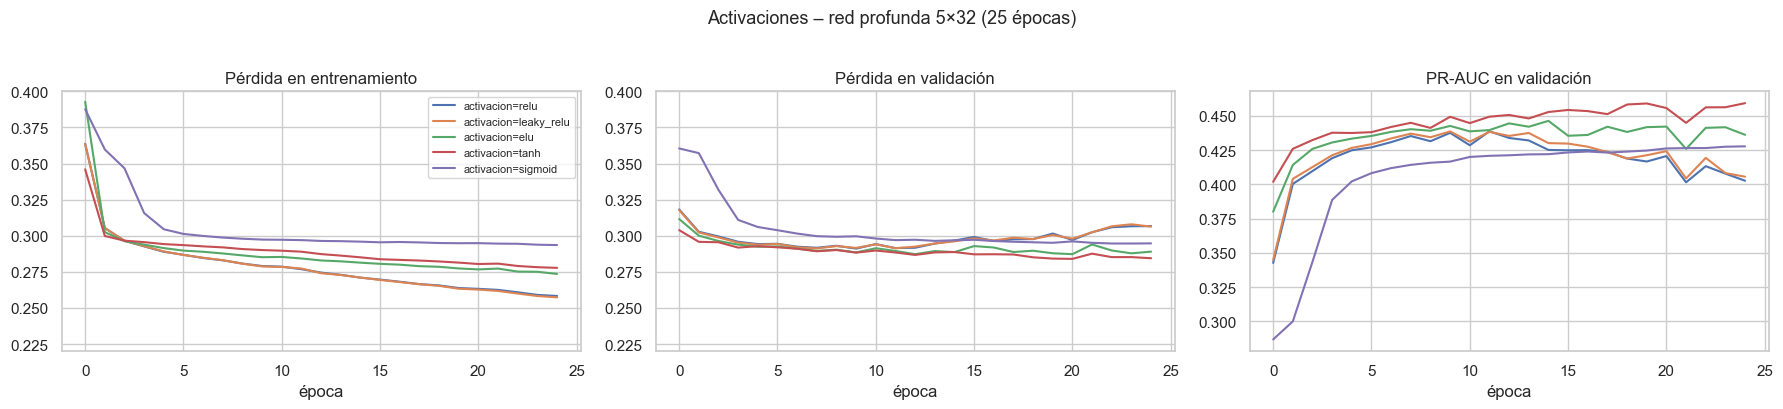

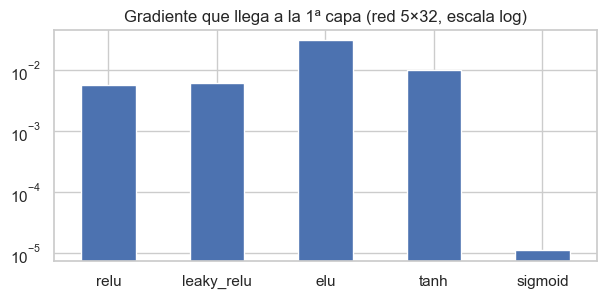

,accuracy,precision,recall,f1,roc_auc,pr_auc,épocas,seg,val_loss mín,época val_loss mín,PR-AUC máx,época PR-AUC máx
activacion=relu,0.8875,0.5325,0.3102,0.3920,0.7686,0.4027,25,11.9,0.2911,10,0.4388,12
activacion=leaky_relu,0.8885,0.5427,0.2963,0.3834,0.7708,0.4056,25,11.7,0.2912,8,0.4387,10
activacion=elu,0.8937,0.5994,0.2736,0.3758,0.7916,0.4362,25,13.0,0.2872,13,0.4464,15
activacion=tanh,0.8959,0.6399,0.2509,0.3605,0.7982,0.4593,25,12.0,0.2840,21,0.4593,25
activacion=sigmoid,0.8924,0.5887,0.2636,0.3641,0.7792,0.4278,25,13.0,0.2946,24,0.4278,25


In [25]:
# Red profunda: 5 capas ocultas -> el efecto de la saturación se acumula capa a capa
tabla_act_prof, hist_act_prof = experimento("activacion", ACTS, capas=(32,) * 5, epocas=25)
graficar_historias(hist_act_prof, "Activaciones – red profunda 5×32 (25 épocas)", ylim_loss=(0.22, 0.40))

# Magnitud media del gradiente en la PRIMERA capa al inicio del entrenamiento
def norma_grad_primera_capa(act, capas=(32,) * 5):
    fijar_semilla(); m = MLP(N_FEAT, capas, act).to(DEVICE)
    loss = nn.BCEWithLogitsLoss()(m(Xtr_t[:2048]), ytr_t[:2048]); loss.backward()
    return m.ocultas[0].weight.grad.abs().mean().item()

grad_df = pd.Series({a: norma_grad_primera_capa(a) for a in ACTS}, name="|grad| medio capa 1")
grad_df.plot(kind="bar", rot=0, figsize=(7, 3), logy=True, title="Gradiente que llega a la 1ª capa (red 5×32, escala log)")
plt.show()
resaltar(tabla_act_prof)

**Análisis (activaciones):**
- En la red poco profunda, **ReLU, Leaky ReLU y ELU** obtienen resultados muy parecidos y convergen rápido; **tanh** es competitiva pero algo más lenta; la **sigmoide** es la que converge más lento.
- En la red profunda la diferencia se amplifica: el gráfico de barras muestra que el gradiente que llega a la primera capa con **sigmoide es órdenes de magnitud menor** que con ReLU (su derivada máxima es 0,25 y se multiplica en cada capa). Es la evidencia experimental del **desvanecimiento del gradiente** visto en la sección 5.
- Leaky ReLU y ELU no muestran una ventaja significativa sobre ReLU en este problema (no se observan neuronas muertas que afecten el desempeño).

**Decisión:** **ReLU** en las capas ocultas: mejor o igual desempeño, convergencia rápida, menor costo de cómputo y gradientes estables. **Sigmoide sólo en la salida**, donde su rango (0, 1) se interpreta como la **probabilidad de que el cliente contrate**, que es justamente lo que el banco necesita para priorizar llamadas.

## 9. Comparación de funciones de pérdida (error)

Se mantiene la arquitectura base con ReLU y se cambia sólo la pérdida. Como cada pérdida tiene una escala distinta, **no se comparan sus valores** sino las métricas de clasificación en validación. Se usa early stopping (paciencia 8) para comparar a cada una en su mejor punto.

perdida=bce                PR-AUC final=0.4340 | PR-AUC máx=0.4361 (época 13) | 6.1s
perdida=bce_ponderada      PR-AUC final=0.4432 | PR-AUC máx=0.4461 (época 13) | 7.7s
perdida=focal              PR-AUC final=0.4358 | PR-AUC máx=0.4394 (época 15) | 6.5s
perdida=mse                PR-AUC final=0.4379 | PR-AUC máx=0.4381 (época 17) | 8.4s


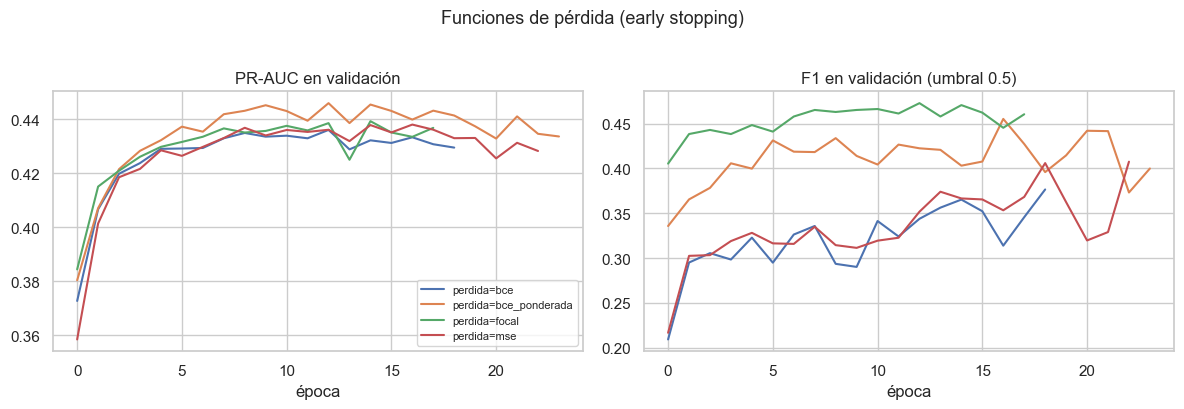

,accuracy,precision,recall,f1,roc_auc,pr_auc,épocas,seg,val_loss mín,época val_loss mín,PR-AUC máx,época PR-AUC máx
perdida=bce,0.8902,0.5710,0.2434,0.3413,0.7944,0.4340,19,6.1,0.2890,11,0.4361,13
perdida=bce_ponderada,0.7746,0.2942,0.6633,0.4076,0.7946,0.4432,24,7.7,0.9586,16,0.4461,13
perdida=focal,0.8813,0.4916,0.4414,0.4651,0.7888,0.4358,18,6.5,0.0377,10,0.4394,15
perdida=mse,0.8919,0.5824,0.2673,0.3665,0.7949,0.4379,23,8.4,0.0828,17,0.4381,17


In [26]:
PERDIDAS = ["bce", "bce_ponderada", "focal", "mse"]
tabla_loss, hist_loss = experimento("perdida", PERDIDAS, epocas=80, paciencia=8)
graficar_historias(hist_loss, "Funciones de pérdida (early stopping)", claves=("val_pr_auc", "val_f1"))
resaltar(tabla_loss)

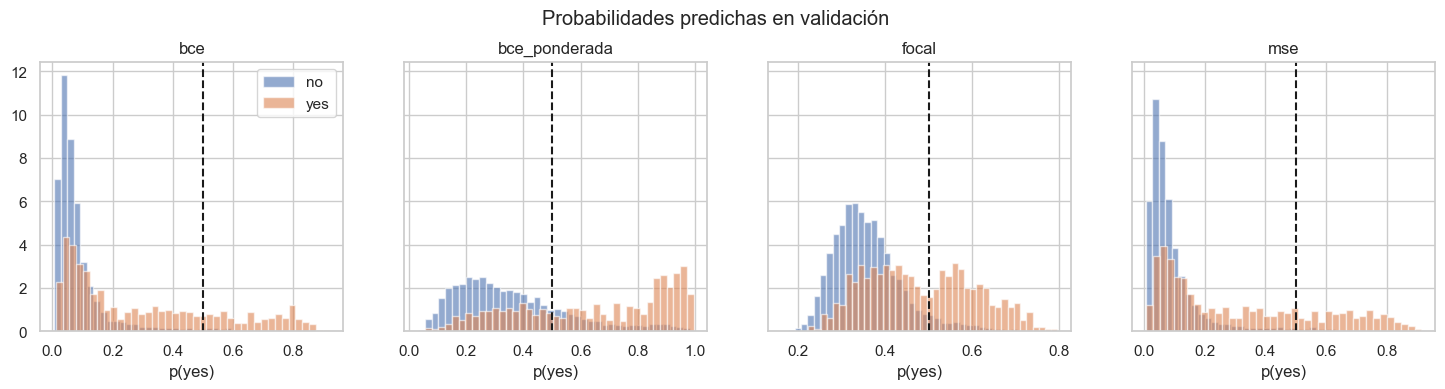

In [27]:
# Distribución de las probabilidades predichas en validación según la pérdida
fig, axes = plt.subplots(1, 4, figsize=(18, 3.5), sharey=True)
for ax, perd in zip(axes, PERDIDAS):
    m, _, _, _ = entrenar(perdida=perd, epocas=80, paciencia=8)
    p_v = predecir_proba(m, Xva_t)
    ax.hist(p_v[y_val == 0], bins=40, alpha=.6, density=True, label="no")
    ax.hist(p_v[y_val == 1], bins=40, alpha=.6, density=True, label="yes")
    ax.axvline(0.5, c="k", ls="--"); ax.set_title(perd); ax.set_xlabel("p(yes)")
axes[0].legend(); plt.suptitle("Probabilidades predichas en validación", y=1.03); plt.show()

**Análisis (pérdidas):**
- **BCE:** buen ranking (PR-AUC), pero probabilidades concentradas por debajo de 0,5 → con umbral 0,5 tiene **precision alta y recall muy bajo**.
- **BCE ponderada** (`pos_weight ≈ 7,5`): cada positivo "pesa" como 7,5 negativos, desplaza las probabilidades hacia arriba → **recall mucho mayor** y mejor F1 a umbral 0,5, a costa de precisión. Su PR-AUC es similar a BCE: la ponderación cambia principalmente **dónde cae el umbral**, no la capacidad de ordenar clientes.
- **Focal loss:** también mejora el recall al concentrarse en los ejemplos difíciles (los positivos minoritarios).
- **MSE:** la de peor desempeño/convergencia, consistente con el análisis teórico (gradiente que se anula cuando la sigmoide se satura).

**Decisión:** **BCE ponderada** como pérdida final. Es la función de máxima verosimilitud correcta para una salida binaria (sigmoide), estable numéricamente (`BCEWithLogitsLoss`) y la ponderación incorpora el requerimiento del negocio: **perder un cliente que sí habría contratado (falso negativo) es más costoso que hacer una llamada extra (falso positivo)**. El umbral se ajustará luego en validación.

## 10. Optimización y regularización

En la sección 7.1 vimos que el modelo **sobreajusta**. Evaluamos técnicas para mejorar la **estabilidad** y la **capacidad de generalización**. Para que el efecto sea visible se entrena una red **más grande (128 → 64 → 32)** durante **60 épocas sin early stopping**, con BCE ponderada:

| Técnica | Cómo actúa |
|---|---|
| **Dropout (p=0.3)** | Apaga al azar el 30 % de las neuronas en cada paso → la red no puede depender de neuronas concretas (ensamble implícito). |
| **Batch Normalization** | Normaliza las activaciones de cada capa por mini-batch → gradientes mejor condicionados, permite convergencia más estable. |
| **L2 / weight decay (1e-4)** | Penaliza pesos grandes → funciones más suaves, menos sensibles al ruido. |
| **Combinación** | Dropout + BatchNorm + L2. |

Sin regularización     PR-AUC=0.3137  brecha=1.5486
Dropout 0.3            PR-AUC=0.4371  brecha=0.1075
BatchNorm              PR-AUC=0.3278  brecha=1.6639
L2 1e-4                PR-AUC=0.3308  brecha=1.3709
Dropout+BN+L2          PR-AUC=0.4545  brecha=0.0555


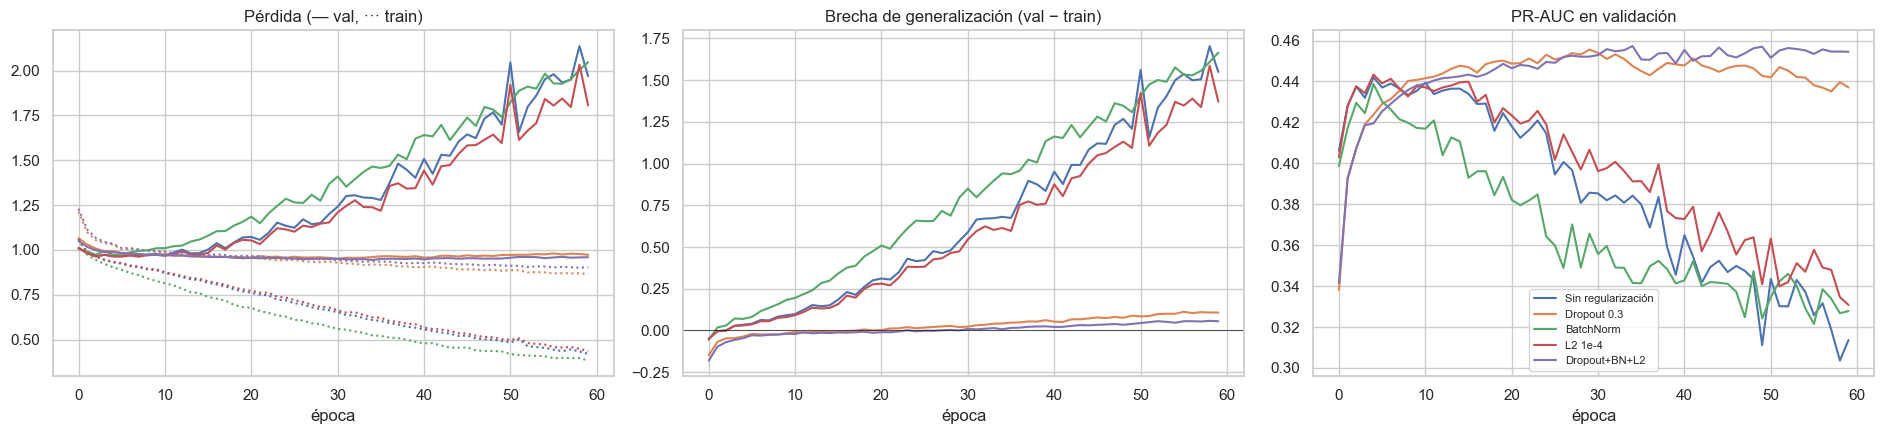

,pr_auc,roc_auc,f1,precision,recall,val_loss mín,val_loss final,brecha final (val-train),std PR-AUC últimas 15 ép.
Sin regularización,0.3137,0.7287,0.3518,0.2539,0.5725,0.9642,1.9691,1.5486,0.0141
Dropout 0.3,0.4371,0.7898,0.4156,0.3037,0.6583,0.9514,0.9732,0.1075,0.0041
BatchNorm,0.3278,0.7272,0.3696,0.2921,0.5032,0.9702,2.0473,1.6639,0.0080
L2 1e-4,0.3308,0.7351,0.3663,0.2656,0.5902,0.9632,1.8067,1.3709,0.0108
Dropout+BN+L2,0.4545,0.7934,0.4331,0.3271,0.6406,0.9445,0.9596,0.0555,0.0016


In [28]:
CFG_REG = dict(capas=(128, 64, 32), perdida="bce_ponderada", epocas=60)
variantes = {
    "Sin regularización": {},
    "Dropout 0.3": dict(dropout=0.3),
    "BatchNorm": dict(batchnorm=True),
    "L2 1e-4": dict(l2=1e-4),
    "Dropout+BN+L2": dict(dropout=0.3, batchnorm=True, l2=1e-4),
}
filas_reg, hist_reg = {}, {}
for nombre, extra in variantes.items():
    _, h, r, _ = entrenar(CFG_REG, **extra)
    # brecha de generalización: pérdida val - pérdida train al final del entrenamiento
    r["brecha final (val-train)"] = h["val_loss"][-1] - h["train_loss"][-1]
    r["val_loss mín"] = min(h["val_loss"]); r["val_loss final"] = h["val_loss"][-1]
    r["std PR-AUC últimas 15 ép."] = np.std(h["val_pr_auc"][-15:])
    filas_reg[nombre], hist_reg[nombre] = r, h
    print(f"{nombre:<22} PR-AUC={r['pr_auc']:.4f}  brecha={r['brecha final (val-train)']:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(19, 4.5))
for nombre, h in hist_reg.items():
    l, = axes[0].plot(h["val_loss"], label=nombre)
    axes[0].plot(h["train_loss"], ls=":", c=l.get_color())
    axes[1].plot(np.array(h["val_loss"]) - np.array(h["train_loss"]), label=nombre)
    axes[2].plot(h["val_pr_auc"], label=nombre)
axes[0].set(title="Pérdida (— val, ··· train)", xlabel="época")
axes[1].set(title="Brecha de generalización (val − train)", xlabel="época"); axes[1].axhline(0, c="k", lw=.5)
axes[2].set(title="PR-AUC en validación", xlabel="época")
axes[2].legend(fontsize=8); plt.tight_layout(); plt.show()

tabla_reg = pd.DataFrame(filas_reg).T
tabla_reg[["pr_auc", "roc_auc", "f1", "precision", "recall", "val_loss mín", "val_loss final",
           "brecha final (val-train)", "std PR-AUC últimas 15 ép."]].style.format("{:.4f}") \
    .highlight_max(subset=["pr_auc", "roc_auc", "f1"], color="#c6efce") \
    .highlight_min(subset=["val_loss final", "brecha final (val-train)", "std PR-AUC últimas 15 ép."], color="#c6efce")

**Análisis (regularización):**
- **Sin regularización** la brecha val − train crece sin parar y el PR-AUC de validación **cae** después de las primeras épocas: sobreajuste claro.
- **Dropout** es la técnica individual más efectiva: mantiene la pérdida de validación baja y estable, reduce fuertemente la brecha y conserva el mejor PR-AUC al final del entrenamiento.
- **L2** con este valor tiene un efecto moderado: frena el crecimiento de los pesos y retrasa el sobreajuste.
- **BatchNorm** acelera la convergencia, pero **por sí sola no regulariza lo suficiente** en una red de este tamaño (su ruido de mini-batch es pequeño con batch 256).
- La **combinación** produce las curvas más estables (menor variación del PR-AUC entre épocas) y la menor brecha, es decir, un modelo cuyo desempeño **no depende de detenerse en la época exacta**.

**Decisión:** el modelo final usará **Dropout + L2** (y se evalúa BatchNorm en la búsqueda de la sección 11), siempre con **early stopping** como red de seguridad.

### 10.1 Comparación de optimizadores

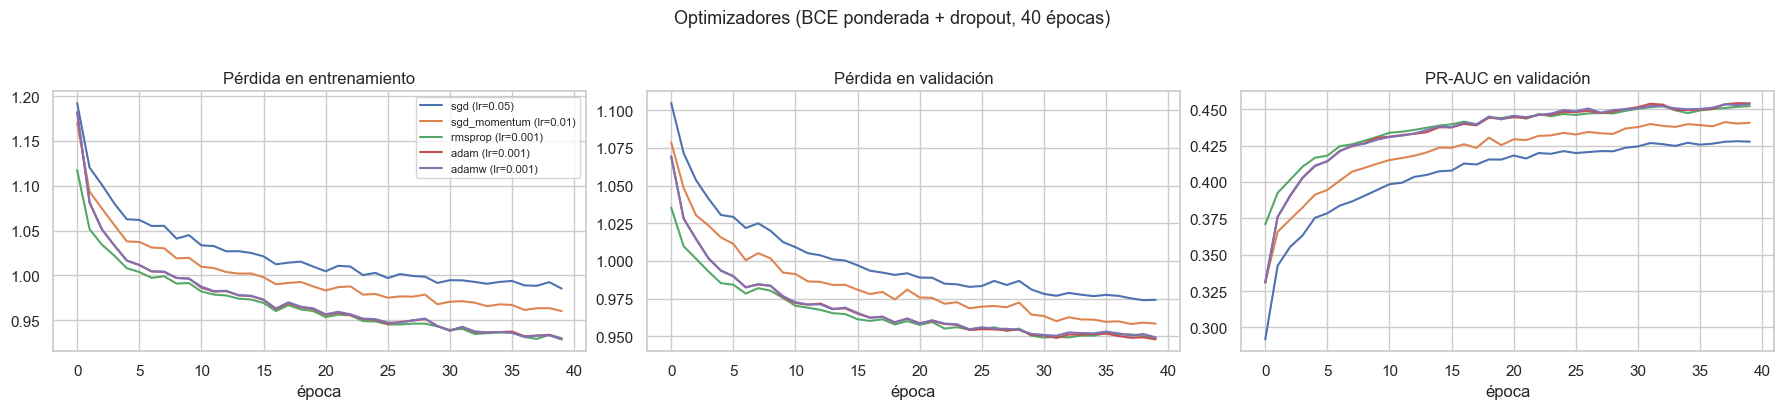

,accuracy,precision,recall,f1,roc_auc,pr_auc,épocas,seg
sgd (lr=0.05),0.8024,0.3190,0.6078,0.4184,0.7872,0.4276,40,15.5
sgd_momentum (lr=0.01),0.8027,0.3232,0.6280,0.4267,0.7945,0.4406,40,16.8
rmsprop (lr=0.001),0.8121,0.3365,0.6242,0.4373,0.7988,0.4521,40,17.4
adam (lr=0.001),0.7970,0.3177,0.6419,0.4251,0.7997,0.4540,40,19.3
adamw (lr=0.001),0.7973,0.3170,0.6356,0.4230,0.7985,0.4535,40,20.5


In [29]:
OPTS = {"sgd": 0.05, "sgd_momentum": 0.01, "rmsprop": 1e-3, "adam": 1e-3, "adamw": 1e-3}
filas_opt, hist_opt = {}, {}
for opt_, lr_ in OPTS.items():
    _, h, r, _ = entrenar(perdida="bce_ponderada", dropout=0.3, optimizador=opt_, lr=lr_, l2=1e-4, epocas=40)
    filas_opt[f"{opt_} (lr={lr_})"], hist_opt[f"{opt_} (lr={lr_})"] = r, h
graficar_historias(hist_opt, "Optimizadores (BCE ponderada + dropout, 40 épocas)", claves=("train_loss", "val_loss", "val_pr_auc"))
resaltar(pd.DataFrame(filas_opt).T)

**Análisis (optimizadores):** **SGD** sin momentum es el más lento en converger; agregar **momentum (Nesterov)** acelera notablemente. Los métodos **adaptativos (RMSprop, Adam, AdamW)** convergen más rápido y llegan a resultados equivalentes o mejores, porque ajustan el paso de cada peso según la historia de sus gradientes (útil con entradas One-Hot, donde muchas columnas son casi siempre 0). **Decisión:** **Adam**, por su rapidez y robustez sin necesidad de ajustar fino el lr.

## 11. Arquitectura y ajuste de hiperparámetros

Con las decisiones anteriores (ReLU, BCE ponderada, Adam, early stopping) ajustamos la **arquitectura** (número de capas y neuronas) y luego realizamos una **búsqueda en grilla** pequeña sobre los hiperparámetros con mayor impacto observado: **tasa de aprendizaje, dropout, batch size y batch normalization**. Todas las configuraciones se comparan en **validación** (nunca en test).

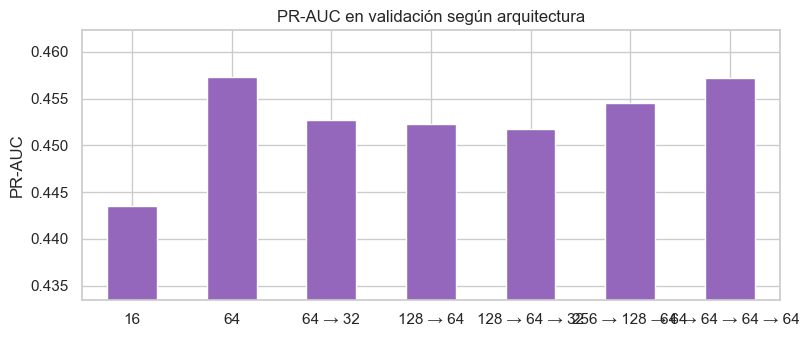

,accuracy,precision,recall,f1,roc_auc,pr_auc,épocas,seg,parámetros
16,0.8040,0.3241,0.6230,0.4264,0.7942,0.4435,62,18.1,849
64,0.7939,0.3159,0.6545,0.4261,0.8040,0.4573,66,24.0,"3,393"
64 → 32,0.7970,0.3191,0.6494,0.4279,0.8017,0.4527,55,25.6,"5,441"
128 → 64,0.7989,0.3192,0.6356,0.4250,0.7967,0.4523,31,19.3,"14,977"
128 → 64 → 32,0.7940,0.3156,0.6520,0.4253,0.7972,0.4517,39,30.2,"17,025"
256 → 128 → 64,0.8198,0.3490,0.6255,0.4481,0.8012,0.4545,25,29.4,"54,529"
64 → 64 → 64 → 64,0.8096,0.3351,0.6381,0.4394,0.8018,0.4572,48,42.6,"15,873"


In [30]:
BASE_TUNE = dict(perdida="bce_ponderada", dropout=0.3, l2=1e-4, epocas=150, paciencia=8)
ARQS = [(16,), (64,), (64, 32), (128, 64), (128, 64, 32), (256, 128, 64), (64, 64, 64, 64)]
filas_arq = {}
for capas in ARQS:
    _, h, r, _ = entrenar(BASE_TUNE, capas=capas)
    r["parámetros"] = sum(p.numel() for p in MLP(N_FEAT, capas).parameters())
    filas_arq[" → ".join(map(str, capas))] = r
tabla_arq = pd.DataFrame(filas_arq).T
fig, ax = plt.subplots(figsize=(9, 3.5))
tabla_arq["pr_auc"].plot(kind="bar", ax=ax, rot=0, color="tab:purple")
ax.set_ylim(tabla_arq.pr_auc.min() - 0.01, tabla_arq.pr_auc.max() + 0.005)
ax.set(title="PR-AUC en validación según arquitectura", ylabel="PR-AUC"); plt.show()
resaltar(tabla_arq).format("{:,.0f}", subset=["parámetros"])

**Análisis (arquitectura):** una sola capa pequeña (16) tiene poca capacidad, pero a partir de 2 capas las diferencias son pequeñas: el problema es **tabular y de dimensión moderada**, por lo que más profundidad no aporta mucho y sólo aumenta parámetros y riesgo de sobreajuste. Elegimos la arquitectura con mejor PR-AUC de validación; ante empates, se prefiere la **más simple** (principio de parsimonia).

In [31]:
# Regla de parsimonia: entre las arquitecturas a menos de 0.003 de PR-AUC de la mejor, se elige la de menos parámetros
TOL = 0.003
candidatas = tabla_arq[tabla_arq["pr_auc"] >= tabla_arq["pr_auc"].max() - TOL]
idx_arq = list(tabla_arq.index).index(candidatas["parámetros"].idxmin())
mejor_arq = ARQS[idx_arq]
print("Arquitecturas candidatas (a menos de", TOL, "del mejor PR-AUC):", list(candidatas.index))
print("Arquitectura seleccionada (menos parámetros):", mejor_arq)

import itertools
grilla = dict(activacion=["relu", "tanh"], lr=[1e-3, 3e-3], dropout=[0.2, 0.4],
              batch_size=[128, 512], batchnorm=[False, True])
filas_grid = []
for act_, lr_, do_, bs_, bn_ in itertools.product(*grilla.values()):
    _, h, r, _ = entrenar(BASE_TUNE, capas=mejor_arq, activacion=act_, lr=lr_, dropout=do_, batch_size=bs_, batchnorm=bn_)
    filas_grid.append({"activacion": act_, "lr": lr_, "dropout": do_, "batch_size": bs_, "batchnorm": bn_, **r})
tabla_grid = pd.DataFrame(filas_grid).sort_values("pr_auc", ascending=False).reset_index(drop=True)
print(f"{len(tabla_grid)} configuraciones evaluadas")
tabla_grid.head(10).style.format("{:.4f}", subset=["precision", "recall", "f1", "accuracy", "roc_auc", "pr_auc"]) \
    .format("{:.1f}", subset=["seg"]).background_gradient(subset=["pr_auc"], cmap="Greens")

Arquitecturas candidatas (a menos de 0.003 del mejor PR-AUC): ['64', '256 → 128 → 64', '64 → 64 → 64 → 64']
Arquitectura seleccionada (menos parámetros): (64,)
32 configuraciones evaluadas


,activacion,lr,dropout,batch_size,batchnorm,accuracy,precision,recall,f1,roc_auc,pr_auc,épocas,seg
0,relu,0.003000,0.400000,512,True,0.8027,0.3259,0.6431,0.4326,0.8032,0.4594,56,17.3
1,relu,0.001000,0.400000,128,False,0.7964,0.3183,0.6494,0.4272,0.8027,0.4573,58,36.2
2,relu,0.003000,0.400000,128,False,0.7917,0.3141,0.6608,0.4258,0.8008,0.4561,28,17.3
3,relu,0.001000,0.400000,512,True,0.8021,0.3248,0.6419,0.4314,0.8002,0.4558,81,23.1
4,relu,0.003000,0.400000,128,True,0.8030,0.3261,0.6419,0.4325,0.8020,0.4557,27,32.2
5,tanh,0.001000,0.200000,128,True,0.7802,0.3026,0.6747,0.4178,0.7954,0.4549,41,31.5
6,relu,0.001000,0.400000,512,False,0.8002,0.3235,0.6494,0.4319,0.8002,0.4549,63,15.0
7,relu,0.001000,0.400000,128,True,0.8063,0.3285,0.6293,0.4317,0.8017,0.4548,63,51.9
8,relu,0.001000,0.200000,512,False,0.7976,0.3185,0.6419,0.4258,0.8000,0.4546,63,16.0
9,relu,0.001000,0.200000,512,True,0.7976,0.3185,0.6419,0.4258,0.7994,0.4543,63,18.3


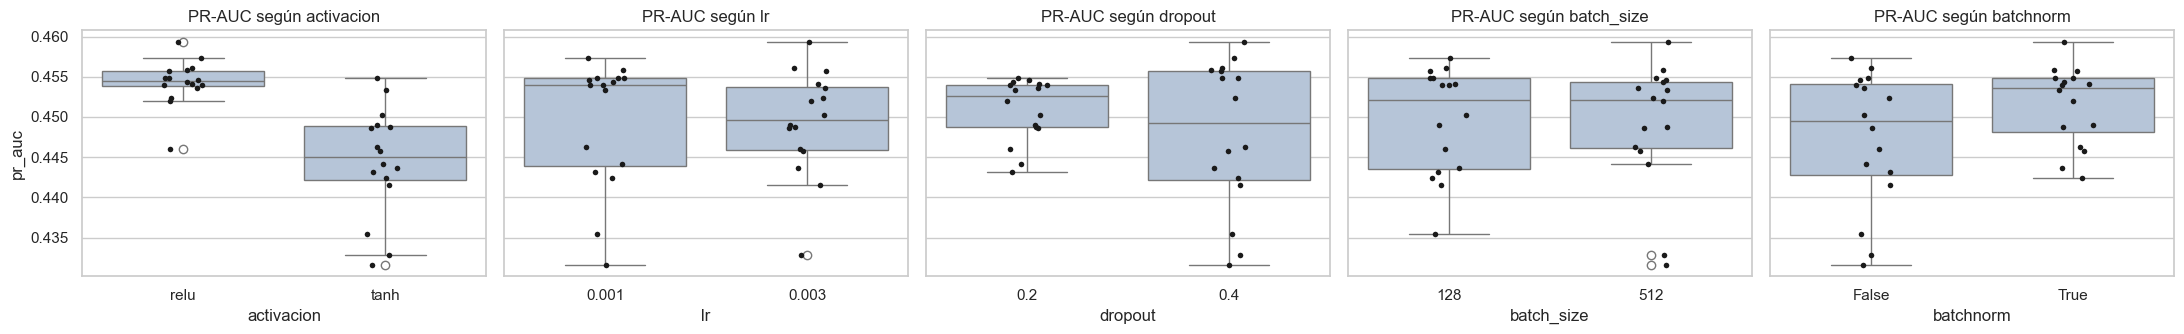

pr_auc     f1  épocas
activacion  relu   0.4543 0.4260 47.8750
            tanh   0.4445 0.4098 55.6250
lr         0.0010  0.4494 0.4188 65.0000
           0.0030  0.4494 0.4170 38.5000
dropout    0.2000  0.4509 0.4165 48.8750
           0.4000  0.4479 0.4194 54.6250
batch_size  128    0.4495 0.4181 44.6250
            512    0.4493 0.4178 58.8750
batchnorm   False  0.4473 0.4137 54.7500
            True   0.4515 0.4221 48.7500

In [32]:
# Efecto marginal (promedio) de cada hiperparámetro sobre el PR-AUC de validación
fig, axes = plt.subplots(1, 5, figsize=(22, 3.5), sharey=True)
for ax, hp in zip(axes, grilla):
    sns.boxplot(data=tabla_grid, x=hp, y="pr_auc", ax=ax, color="lightsteelblue")
    sns.stripplot(data=tabla_grid, x=hp, y="pr_auc", ax=ax, color="k", size=4)
    ax.set_title(f"PR-AUC según {hp}")
plt.tight_layout(); plt.show()
pd.concat({hp: tabla_grid.groupby(hp)[["pr_auc", "f1", "épocas"]].mean() for hp in grilla})

In [33]:
mejor_cfg = tabla_grid.iloc[0]
CFG_FINAL = dict(BASE_TUNE, capas=mejor_arq, activacion=mejor_cfg.activacion, lr=float(mejor_cfg.lr), dropout=float(mejor_cfg.dropout),
                 batch_size=int(mejor_cfg.batch_size), batchnorm=bool(mejor_cfg.batchnorm), scheduler=True)
print("Configuración final:")
for k, v in CFG_FINAL.items(): print(f"  {k:<12} = {v}")

Configuración final:
  perdida      = bce_ponderada
  dropout      = 0.4
  l2           = 0.0001
  epocas       = 150
  paciencia    = 8
  capas        = (64,)
  activacion   = relu
  lr           = 0.003
  batch_size   = 512
  batchnorm    = True
  scheduler    = True


**Análisis (hiperparámetros):** los gráficos muestran el efecto **promedio** de cada hiperparámetro sobre todas las combinaciones de los demás. Las diferencias entre las mejores configuraciones son pequeñas (del orden de centésimas de PR-AUC), lo que indica que, una vez resueltos los problemas importantes (desbalance y sobreajuste), el modelo es **robusto** frente a estos valores. Se adopta la mejor combinación de la grilla y se agrega el scheduler `ReduceLROnPlateau` para afinar el lr al final del entrenamiento.

**Justificación de los valores elegidos:** se muestran en la celda anterior; cada uno corresponde a la combinación de mayor PR-AUC en validación, en coherencia con lo observado en los experimentos individuales (lr intermedio estable, dropout moderado para controlar el sobreajuste, batch intermedio).

## 12. Modelo final: entrenamiento, umbral de decisión y evaluación en test

### 12.1 Reentrenamiento con la configuración final

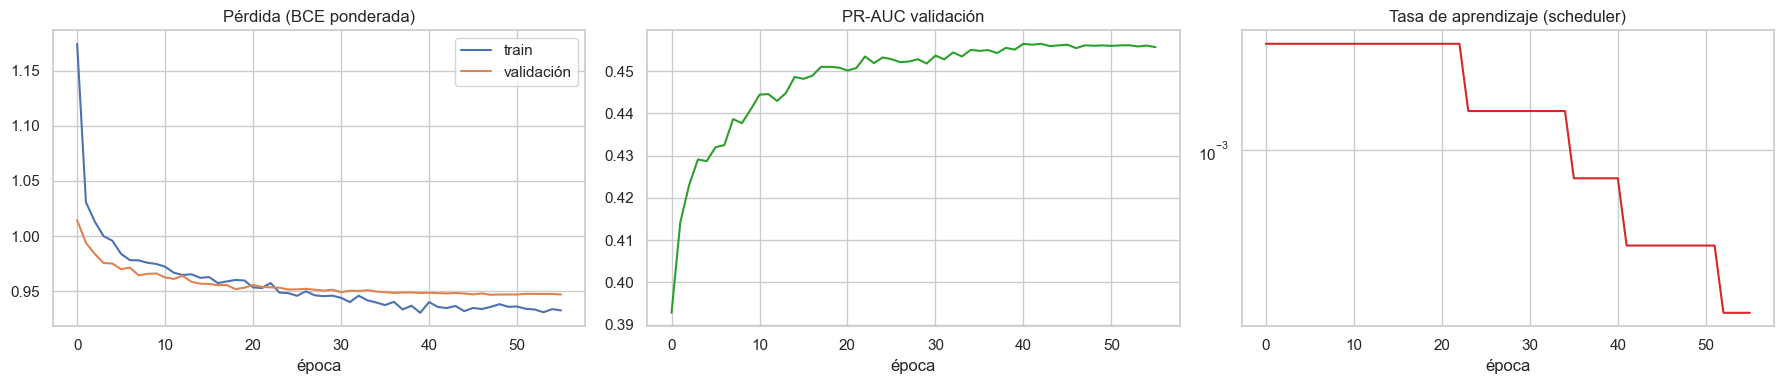

Entrenado en 56 épocas (18.8s). Early stopping restauró los mejores pesos.
MLP(
  (ocultas): Sequential(
    (0): Linear(in_features=51, out_features=64, bias=True)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.4, inplace=False)
  )
  (salida): Linear(in_features=64, out_features=1, bias=True)
)


In [34]:
modelo_final, hist_final, res_final_val, seg_final = entrenar(CFG_FINAL)
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].plot(hist_final["train_loss"], label="train"); axes[0].plot(hist_final["val_loss"], label="validación")
axes[0].set(title="Pérdida (BCE ponderada)", xlabel="época"); axes[0].legend()
axes[1].plot(hist_final["val_pr_auc"], c="tab:green"); axes[1].set(title="PR-AUC validación", xlabel="época")
axes[2].plot(hist_final["lr"], c="tab:red"); axes[2].set(title="Tasa de aprendizaje (scheduler)", xlabel="época", yscale="log")
plt.tight_layout(); plt.show()
print(f"Entrenado en {res_final_val['épocas']} épocas ({seg_final:.1f}s). Early stopping restauró los mejores pesos.")
print(modelo_final)

### 12.2 Selección del umbral de decisión (en validación)

La red entrega una **probabilidad**; el umbral 0,5 es arbitrario y, con pérdida ponderada, no es necesariamente el mejor. Buscamos en **validación** el umbral que **maximiza el F1-Score** (equilibrio entre precision y recall). Hacerlo en validación —y no en test— evita sobreestimar el desempeño final.

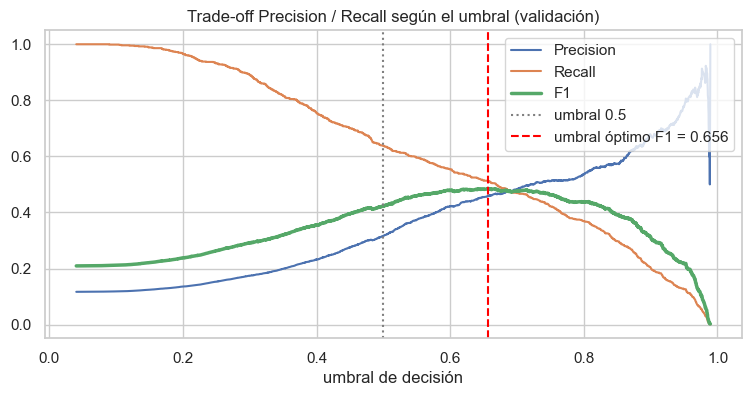

,accuracy,precision,recall,f1,roc_auc,pr_auc
umbral 0.5,0.7965,0.3164,0.6381,0.4231,0.8003,0.4561
umbral 0.656,0.8728,0.4604,0.5132,0.4854,0.8003,0.4561


In [35]:
p_val_final = predecir_proba(modelo_final, Xva_t)
prec_c, rec_c, umb_c = precision_recall_curve(y_val, p_val_final)
f1_c = 2 * prec_c[:-1] * rec_c[:-1] / (prec_c[:-1] + rec_c[:-1] + 1e-12)
UMBRAL = float(umb_c[np.argmax(f1_c)])

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(umb_c, prec_c[:-1], label="Precision"); ax.plot(umb_c, rec_c[:-1], label="Recall"); ax.plot(umb_c, f1_c, label="F1", lw=2.5)
ax.axvline(0.5, c="gray", ls=":", label="umbral 0.5"); ax.axvline(UMBRAL, c="red", ls="--", label=f"umbral óptimo F1 = {UMBRAL:.3f}")
ax.set(xlabel="umbral de decisión", title="Trade-off Precision / Recall según el umbral (validación)"); ax.legend()
plt.show()
pd.DataFrame({"umbral 0.5": metricas(y_val, p_val_final, 0.5), f"umbral {UMBRAL:.3f}": metricas(y_val, p_val_final, UMBRAL)}).T

### 12.3 Evaluación final en el conjunto de prueba (test)

El conjunto de test **no se ha usado en ninguna decisión anterior**. Se compara contra tres referencias: un clasificador trivial (siempre "no"), una **regresión logística** de scikit-learn (modelo lineal clásico) y el **MLP base** de la sección 7.

In [36]:
p_test = predecir_proba(modelo_final, Xte_t)
p_test_base = predecir_proba(modelo_base, Xte_t)
logreg = LogisticRegression(max_iter=2000, class_weight="balanced").fit(X_train, y_train)
p_test_lr = logreg.predict_proba(X_test)[:, 1]
p_val_lr = logreg.predict_proba(X_val)[:, 1]
pr, rc, th = precision_recall_curve(y_val, p_val_lr); umb_lr = th[np.argmax(2*pr[:-1]*rc[:-1]/(pr[:-1]+rc[:-1]+1e-12))]

resumen = pd.DataFrame({
    "Trivial (siempre 'no')": metricas(y_test, np.zeros_like(y_test)),
    "Regresión logística (umbral óptimo val)": metricas(y_test, p_test_lr, umb_lr),
    "MLP base (BCE, umbral 0.5)": metricas(y_test, p_test_base, 0.5),
    "MLP final (umbral 0.5)": metricas(y_test, p_test, 0.5),
    f"MLP final (umbral {UMBRAL:.3f})": metricas(y_test, p_test, UMBRAL),
}).T
resumen.style.format("{:.4f}").highlight_max(color="#c6efce").set_caption("Cuadro resumen de métricas en TEST")

,accuracy,precision,recall,f1,roc_auc,pr_auc
Trivial (siempre 'no'),0.8831,0.0000,0.0000,0.0000,0.5000,0.1169
Regresión logística (umbral óptimo val),0.8567,0.4002,0.4527,0.4249,0.7604,0.3839
"MLP base (BCE, umbral 0.5)",0.8928,0.5922,0.2673,0.3684,0.7778,0.3978
MLP final (umbral 0.5),0.7945,0.3090,0.6129,0.4108,0.7890,0.4113
MLP final (umbral 0.656),0.8707,0.4512,0.4893,0.4694,0.7890,0.4113


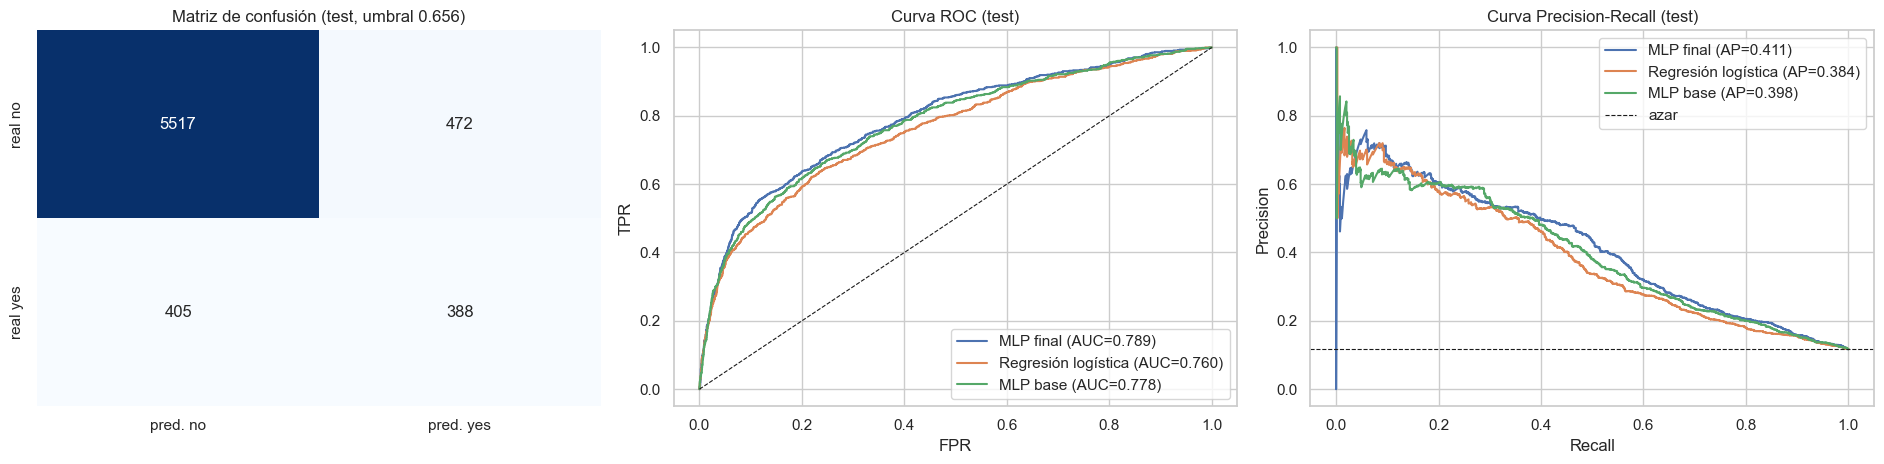

              precision    recall  f1-score   support

          no     0.9316    0.9212    0.9264      5989
         yes     0.4512    0.4893    0.4694       793

    accuracy                         0.8707      6782
   macro avg     0.6914    0.7052    0.6979      6782
weighted avg     0.8754    0.8707    0.8729      6782



In [37]:
pred_test = (p_test >= UMBRAL).astype(int)
cm = confusion_matrix(y_test, pred_test)
tn, fp, fn, tp = cm.ravel()
fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0], cbar=False,
            xticklabels=["pred. no", "pred. yes"], yticklabels=["real no", "real yes"])
axes[0].set_title(f"Matriz de confusión (test, umbral {UMBRAL:.3f})")
for nombre, p_ in [("MLP final", p_test), ("Regresión logística", p_test_lr), ("MLP base", p_test_base)]:
    fpr, tpr, _ = roc_curve(y_test, p_); axes[1].plot(fpr, tpr, label=f"{nombre} (AUC={roc_auc_score(y_test, p_):.3f})")
    pr_, rc_, _ = precision_recall_curve(y_test, p_); axes[2].plot(rc_, pr_, label=f"{nombre} (AP={average_precision_score(y_test, p_):.3f})")
axes[1].plot([0, 1], [0, 1], "k--", lw=.8); axes[1].set(title="Curva ROC (test)", xlabel="FPR", ylabel="TPR"); axes[1].legend()
axes[2].axhline(y_test.mean(), c="k", ls="--", lw=.8, label="azar"); axes[2].set(title="Curva Precision-Recall (test)", xlabel="Recall", ylabel="Precision"); axes[2].legend()
plt.tight_layout(); plt.show()
print(classification_report(y_test, pred_test, target_names=["no", "yes"], digits=4))

### 12.4 Cálculo explícito de cada métrica a partir de la matriz de confusión

| Métrica | Fórmula | Pregunta de negocio que responde |
|---|---|---|
| **Accuracy** | $\frac{TP+TN}{TP+TN+FP+FN}$ | ¿Qué fracción de clientes clasifico bien? (engañosa con desbalance) |
| **Precision** | $\frac{TP}{TP+FP}$ | De los clientes que el modelo manda a llamar, ¿cuántos contratan? → eficiencia del call center |
| **Recall** | $\frac{TP}{TP+FN}$ | De todos los clientes que habrían contratado, ¿a cuántos llegamos? → oportunidades capturadas |
| **F1-Score** | $2\cdot\frac{P\cdot R}{P+R}$ | Media armónica: alta sólo si **ambas** son altas |

In [38]:
acc_m = (tp + tn) / (tp + tn + fp + fn); prec_m = tp / (tp + fp); rec_m = tp / (tp + fn); f1_m = 2 * prec_m * rec_m / (prec_m + rec_m)
print(f"TP={tp}  FP={fp}  FN={fn}  TN={tn}\n")
print(f"Accuracy  = ({tp}+{tn}) / {tp+tn+fp+fn} = {acc_m:.4f}   | sklearn: {accuracy_score(y_test, pred_test):.4f}")
print(f"Precision = {tp} / ({tp}+{fp}) = {prec_m:.4f}            | sklearn: {precision_score(y_test, pred_test):.4f}")
print(f"Recall    = {tp} / ({tp}+{fn}) = {rec_m:.4f}            | sklearn: {recall_score(y_test, pred_test):.4f}")
print(f"F1        = 2·{prec_m:.3f}·{rec_m:.3f}/({prec_m:.3f}+{rec_m:.3f}) = {f1_m:.4f} | sklearn: {f1_score(y_test, pred_test):.4f}")
tasa_base = y_test.mean()
print(f"\nSi el banco llama al azar, convierte el {tasa_base:.1%} de las llamadas.")
print(f"Llamando sólo a quienes el modelo marca como 'yes' ({tp+fp} de {len(y_test)} clientes, {(tp+fp)/len(y_test):.1%}), "
      f"convierte el {prec_m:.1%} (≈{prec_m/tasa_base:.1f}x más eficiente) y captura el {rec_m:.1%} de los contratos.")

TP=388  FP=472  FN=405  TN=5517

Accuracy  = (388+5517) / 6782 = 0.8707   | sklearn: 0.8707
Precision = 388 / (388+472) = 0.4512            | sklearn: 0.4512
Recall    = 388 / (388+405) = 0.4893            | sklearn: 0.4893
F1        = 2·0.451·0.489/(0.451+0.489) = 0.4694 | sklearn: 0.4694

Si el banco llama al azar, convierte el 11.7% de las llamadas.
Llamando sólo a quienes el modelo marca como 'yes' (860 de 6782 clientes, 12.7%), convierte el 45.1% (≈3.9x más eficiente) y captura el 48.9% de los contratos.


## 13. Validación cruzada estratificada (5 folds)

Una única partición puede dar un resultado "con suerte". Para asegurar que el desempeño es **confiable**, repetimos el entrenamiento de la configuración final con **validación cruzada estratificada de 5 folds** sobre train+val (el test sigue intacto). En cada fold el **preprocesador se ajusta de nuevo sólo con los datos de entrenamiento de ese fold** y el umbral se elige con el 15 % interno del fold.

In [39]:
X_cv_df = pd.concat([X_train_df, X_val_df]); y_cv = np.concatenate([y_train, y_val])
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
filas_cv = []
for k, (i_tr, i_te) in enumerate(skf.split(X_cv_df, y_cv), 1):
    i_tr, i_es = train_test_split(i_tr, test_size=0.15, stratify=y_cv[i_tr], random_state=SEED)  # val interna p/ early stopping
    pp = crear_preprocesador().fit(X_cv_df.iloc[i_tr])
    A = lambda idx: to_t(pp.transform(X_cv_df.iloc[idx]).astype(np.float32))
    m, _, _, _ = entrenar(CFG_FINAL, X=A(i_tr), y=to_t(y_cv[i_tr]), Xv=A(i_es), yv=to_t(y_cv[i_es]))
    p_es = predecir_proba(m, A(i_es)); pr, rc, th = precision_recall_curve(y_cv[i_es], p_es)
    u = th[np.argmax(2*pr[:-1]*rc[:-1]/(pr[:-1]+rc[:-1]+1e-12))]
    r = metricas(y_cv[i_te], predecir_proba(m, A(i_te)), u); r["umbral"] = u
    filas_cv.append(r); print(f"Fold {k}: F1={r['f1']:.4f}  PR-AUC={r['pr_auc']:.4f}")
tabla_cv = pd.DataFrame(filas_cv, index=[f"fold {i}" for i in range(1, 6)])
tabla_cv.loc["media"] = tabla_cv.mean(); tabla_cv.loc["desv. estándar"] = tabla_cv.iloc[:5].std()
tabla_cv

Fold 1: F1=0.4749  PR-AUC=0.4252
Fold 2: F1=0.4589  PR-AUC=0.4202
Fold 3: F1=0.4532  PR-AUC=0.4209
Fold 4: F1=0.4971  PR-AUC=0.4500
Fold 5: F1=0.4871  PR-AUC=0.4629


,accuracy,precision,recall,f1,roc_auc,pr_auc,umbral
fold 1,0.8708,0.4526,0.4994,0.4749,0.7896,0.4252,0.6398
fold 2,0.8776,0.4750,0.4438,0.4589,0.7827,0.4202,0.7067
fold 3,0.8647,0.4297,0.4794,0.4532,0.7801,0.4209,0.6324
fold 4,0.8752,0.4707,0.5267,0.4971,0.7991,0.4500,0.6471
fold 5,0.8734,0.4629,0.5139,0.4871,0.7998,0.4629,0.6612
media,0.8723,0.4582,0.4927,0.4742,0.7903,0.4358,0.6574
desv. estándar,0.0049,0.0181,0.0325,0.0185,0.0091,0.0194,0.0295


**Análisis:** la desviación estándar entre folds es pequeña en relación con la media, por lo que el desempeño **no depende de una partición afortunada** y es consistente con el resultado obtenido en test.

## 14. Análisis crítico de métricas y propuestas de mejora

### 14.1 Tabla comparativa de todas las pruebas (validación)

In [40]:
def mejor_de(tabla, grupo):
    t = tabla.copy(); t["experimento"] = grupo; return t
comparativa = pd.concat([
    pd.DataFrame({"Perceptrón NumPy": metricas(y_val, p_val_perc)}).T.assign(experimento="Línea base"),
    mejor_de(tabla_lr, "Tasa de aprendizaje"), mejor_de(tabla_bs, "Batch size"),
    mejor_de(tabla_act, "Activación"), mejor_de(tabla_loss, "Pérdida"),
    mejor_de(tabla_reg, "Regularización"), mejor_de(tabla_arq, "Arquitectura"),
    pd.DataFrame({"MLP FINAL (umbral óptimo)": metricas(y_val, p_val_final, UMBRAL)}).T.assign(experimento="Final"),
])[["experimento", "accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]]
comparativa.style.format("{:.4f}", subset=["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]) \
    .background_gradient(subset=["f1", "pr_auc"], cmap="Greens")

,experimento,accuracy,precision,recall,f1,roc_auc,pr_auc
Perceptrón NumPy,Línea base,0.8930,0.6982,0.1488,0.2453,0.7635,0.4010
lr=0.0001,Tasa de aprendizaje,0.8930,0.6192,0.2194,0.3240,0.7883,0.4299
lr=0.001,Tasa de aprendizaje,0.8906,0.5684,0.2673,0.3636,0.7824,0.4070
lr=0.01,Tasa de aprendizaje,0.8807,0.4816,0.2636,0.3407,0.7240,0.3420
lr=0.05,Tasa de aprendizaje,0.8913,0.6186,0.1841,0.2838,0.7717,0.3896
batch_size=32,Batch size,0.8878,0.5315,0.3405,0.4151,0.7674,0.3929
batch_size=128,Batch size,0.8897,0.5591,0.2686,0.3629,0.7775,0.4060
batch_size=512,Batch size,0.8907,0.5596,0.3077,0.3971,0.7882,0.4256
batch_size=2048,Batch size,0.8921,0.5889,0.2547,0.3556,0.7930,0.4344
activacion=relu,Activación,0.8906,0.5684,0.2673,0.3636,0.7824,0.4070


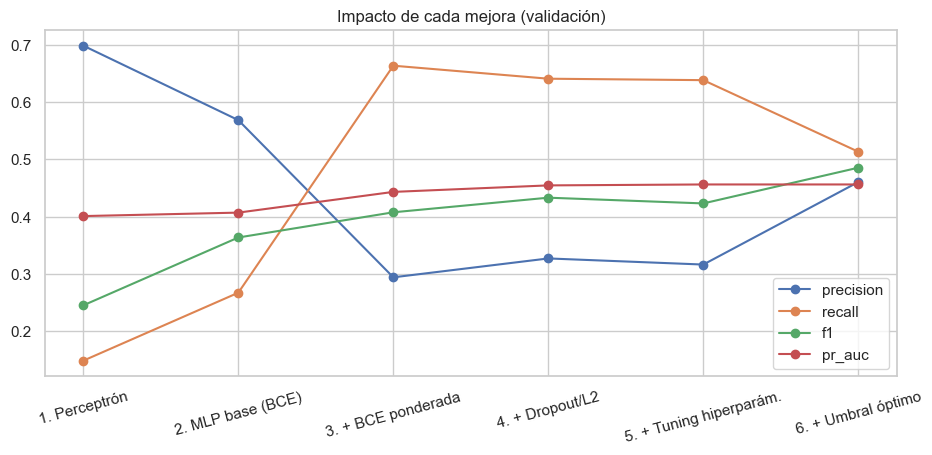

,precision,recall,f1,pr_auc
1. Perceptrón,0.6982,0.1488,0.2453,0.4010
2. MLP base (BCE),0.5684,0.2673,0.3636,0.4070
3. + BCE ponderada,0.2942,0.6633,0.4076,0.4432
4. + Dropout/L2,0.3271,0.6406,0.4331,0.4545
5. + Tuning hiperparám.,0.3164,0.6381,0.4231,0.4561
6. + Umbral óptimo,0.4604,0.5132,0.4854,0.4561


In [41]:
# Evolución del F1 y PR-AUC a lo largo de las mejoras incrementales
etapas = {
    "1. Perceptrón": metricas(y_val, p_val_perc),
    "2. MLP base (BCE)": res_base,
    "3. + BCE ponderada": tabla_loss.loc["perdida=bce_ponderada"].to_dict(),
    "4. + Dropout/L2": tabla_reg.loc["Dropout+BN+L2"].to_dict(),
    "5. + Tuning hiperparám.": res_final_val,
    "6. + Umbral óptimo": metricas(y_val, p_val_final, UMBRAL),
}
ev = pd.DataFrame(etapas).T[["precision", "recall", "f1", "pr_auc"]].astype(float)
ax = ev.plot(marker="o", figsize=(11, 4.5), title="Impacto de cada mejora (validación)")
ax.set_xticks(range(len(ev))); ax.set_xticklabels(ev.index, rotation=15); plt.show()
ev

### 14.2 ¿Cómo mejorar precision y recall? El umbral como palanca de negocio

Precision y recall están en **tensión**: bajar el umbral captura más clientes interesados (↑ recall) a cambio de más llamadas fallidas (↓ precision). El umbral óptimo depende del **costo relativo** para el banco. El siguiente gráfico permite elegirlo según la capacidad del call center:

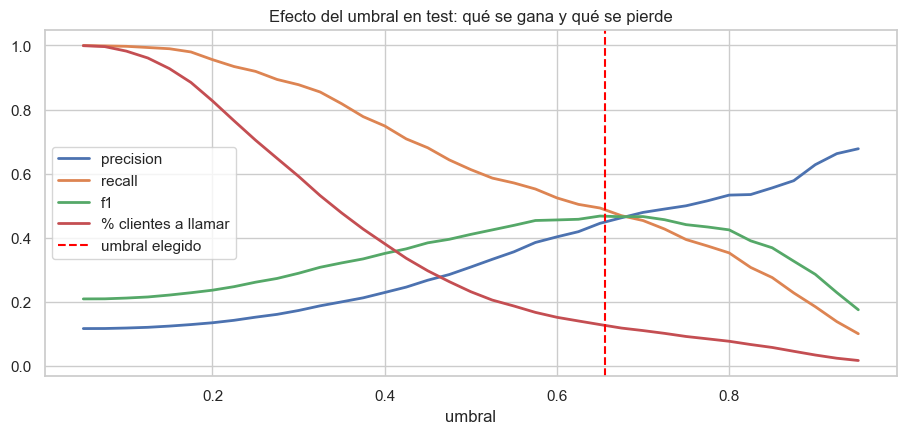

,precision,recall,f1,% clientes a llamar
umbral,,,,
0.1000,0.1187,0.9975,0.2122,0.9825
0.2000,0.1351,0.9559,0.2368,0.8272
0.3000,0.1734,0.8777,0.2896,0.5919
0.4000,0.2295,0.7491,0.3514,0.3816
0.5000,0.3090,0.6129,0.4108,0.2319
0.6000,0.4031,0.5246,0.4559,0.1522


In [42]:
umbrales = np.linspace(0.05, 0.95, 37)
curvas = pd.DataFrame([{**metricas(y_test, p_test, u), "umbral": u, "% clientes a llamar": (p_test >= u).mean()}
                       for u in umbrales]).set_index("umbral")
fig, ax = plt.subplots(figsize=(11, 4.5))
curvas[["precision", "recall", "f1", "% clientes a llamar"]].plot(ax=ax, lw=2)
ax.axvline(UMBRAL, c="red", ls="--", label="umbral elegido")
ax.set(title="Efecto del umbral en test: qué se gana y qué se pierde", xlabel="umbral"); ax.legend(); plt.show()
curvas.loc[curvas.index[[2, 6, 10, 14, 18, 22]], ["precision", "recall", "f1", "% clientes a llamar"]]

### 14.3 Evidencia de la decisión sobre `duration`

Para cuantificar la fuga de información, entrenamos la misma configuración final **incluyendo** `duration`.

In [43]:
datos_d = df.copy(); datos_d["contactado_antes"] = (datos_d.pdays != -1).astype(int); datos_d.loc[datos_d.pdays == -1, "pdays"] = 0
for c in COLS_LOG + ["duration"]: datos_d[c] = np.sign(datos_d[c]) * np.log1p(np.abs(datos_d[c]))
pp_d = ColumnTransformer([("num", StandardScaler(), COLS_NUM + ["duration"]), ("bin", "passthrough", COLS_BIN),
                          ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), COLS_CAT)])
Xd_tr = to_t(pp_d.fit_transform(datos_d.loc[X_train_df.index]).astype(np.float32))
Xd_va = to_t(pp_d.transform(datos_d.loc[X_val_df.index]).astype(np.float32))
_, _, res_dur, _ = entrenar(CFG_FINAL, X=Xd_tr, y=ytr_t, Xv=Xd_va, yv=yva_t)
pd.DataFrame({"Sin duration (modelo realista)": res_final_val, "Con duration (fuga)": res_dur}).T[["precision", "recall", "f1", "roc_auc", "pr_auc"]]

,precision,recall,f1,roc_auc,pr_auc
Sin duration (modelo realista),0.3164,0.6381,0.4231,0.8003,0.4561
Con duration (fuga),0.4148,0.8878,0.5655,0.9289,0.5972


Con `duration` las métricas suben de forma drástica, lo que confirma que es una variable "del futuro": casi revela el resultado. Ese modelo **luce mejor en el papel pero es inutilizable** para decidir a quién llamar. Mantenemos la decisión de excluirla.

### 14.4 Interpretación crítica y propuestas de mejora

**Interpretación de los resultados:**
1. **Accuracy (~0,88–0,90) no es informativa** aquí: es casi la misma del modelo trivial. El valor del modelo está en precision/recall/F1 de la clase "yes".
2. **El MLP supera claramente al azar** (PR-AUC ≈ 0,11 si se ordena aleatoriamente) y al perceptrón lineal, pero la ventaja sobre la regresión logística es moderada. Esto es esperable en datos **tabulares** con pocas variables: buena parte de la señal es aproximadamente lineal tras el One-Hot, y la red aporta sobre todo en las interacciones.
3. **El techo de desempeño lo pone la información disponible**, no la red: sin `duration` las variables describen al cliente pero no su disposición en el momento de la llamada. Por eso más capas o neuronas ya no mejoraban (sección 11).
4. Las mejoras con **mayor impacto** fueron las que atacaron el **desbalance** (pérdida ponderada + umbral) y el **sobreajuste** (dropout/L2/early stopping), más que la arquitectura.

**Propuestas de mejora fundamentadas:**
- **Ingeniería de variables:** codificación cíclica de `month`/`day` (sin y cos), interacciones explícitas (p. ej. `poutcome` × `contactado_antes`), agrupación de categorías raras.
- **Embeddings para categóricas** en lugar de One-Hot (capas `nn.Embedding`), que aprenden representaciones densas de `job` o `month`.
- **Datos adicionales:** la versión `bank-additional` del dataset incluye indicadores **macroeconómicos** (euribor, tasa de empleo) que la literatura reporta como muy predictivos.
- **Remuestreo:** probar SMOTE u *oversampling* de la clase minoritaria como alternativa a la ponderación.
- **Búsqueda de hiperparámetros más amplia** (Optuna / búsqueda bayesiana) y **ensambles** de varias semillas o con modelos de *gradient boosting*, que suelen ser muy fuertes en datos tabulares.
- **Umbral orientado a costos:** definir con el negocio el costo de una llamada y la ganancia de un depósito, y escoger el umbral que maximice la ganancia esperada en vez del F1.
- **Calibración de probabilidades** (Platt / isotónica), ya que la pérdida ponderada distorsiona la probabilidad absoluta, útil si el banco quiere interpretar p(yes) literalmente.

## 15. Conclusiones

- Se implementó un **MLP en PyTorch** para predecir la contratación de un depósito a plazo, con un pipeline de **preprocesamiento sin fuga de información** (exclusión de `duration`, manejo de `pdays=-1`, transformación logarítmica, estandarización y One-Hot ajustados sólo en train, partición estratificada 70/15/15).
- Se programaron **desde cero** las funciones de activación, sus derivadas, las funciones de error y la salida (sigmoide/softmax), verificándolas contra PyTorch, y se entrenó un **perceptrón** en NumPy como línea base.
- Los **experimentos controlados** mostraron que: un lr muy alto acelera el sobreajuste y uno muy bajo no converge; batches pequeños son ruidosos y lentos, y muy grandes requieren más épocas; el número de épocas se resuelve mejor con **early stopping**.
- **ReLU** fue la mejor activación oculta (la **sigmoide** sufre desvanecimiento del gradiente, demostrado midiendo el gradiente en la primera capa); **sigmoide** en la salida entrega la probabilidad de contratación.
- **BCE ponderada** fue la pérdida más adecuada al caso por el **desbalance 1:7,5**, y **MSE** la menos adecuada por su gradiente que se anula.
- **Dropout + L2 + early stopping** redujeron la brecha entre entrenamiento y validación y estabilizaron el desempeño.
- El **ajuste del umbral** en validación fue clave para equilibrar precision y recall; el modelo final permite al banco concentrar sus llamadas en un subconjunto de clientes con una tasa de conversión varias veces superior a la de llamar al azar, capturando una fracción importante de los contratos.
- La **validación cruzada** confirmó que los resultados son estables.
- **Reflexión:** en este problema el mayor aporte vino de **entender los datos y el objetivo de negocio** (fuga de `duration`, desbalance, umbral) más que de hacer la red más grande. Las mejoras futuras deben enfocarse en mejores variables (macroeconómicas, embeddings) y en una métrica de costo definida con el negocio.

## 16. Referencias

- Moro, S., Cortez, P. & Rita, P. (2014). *A data-driven approach to predict the success of bank telemarketing.* Decision Support Systems, 62, 22–31. — [UCI Bank Marketing](https://archive.ics.uci.edu/dataset/222/bank+marketing)
- Documentación oficial de PyTorch: [`torch.nn`](https://pytorch.org/docs/stable/nn.html), [`BCEWithLogitsLoss`](https://pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html), [`torch.optim`](https://pytorch.org/docs/stable/optim.html)
- Documentación de scikit-learn: [Preprocesamiento](https://scikit-learn.org/stable/modules/preprocessing.html), [Métricas](https://scikit-learn.org/stable/modules/model_evaluation.html)
- Kingma, D. & Ba, J. (2015). *Adam: A Method for Stochastic Optimization.* ICLR.
- Srivastava, N. et al. (2014). *Dropout: A Simple Way to Prevent Neural Networks from Overfitting.* JMLR, 15.
- Ioffe, S. & Szegedy, C. (2015). *Batch Normalization.* ICML.
- He, K. et al. (2015). *Delving Deep into Rectifiers* (inicialización He). ICCV.
- Lin, T.-Y. et al. (2017). *Focal Loss for Dense Object Detection.* ICCV.
- Goodfellow, I., Bengio, Y. & Courville, A. (2016). *Deep Learning.* MIT Press.